# Лабораторна робота № 5–6. Нейронна мережа і регуляризація

**Тема:** повнозв'язна нейронна мережа (MLP) з нуля на NumPy, зворотне поширення помилки, збереження/відновлення ваг та дослідження впливу регуляризації (L1, L2, Dropout, weight clipping, gradient clipping) на розподіл ваг, розрідженість, мертві нейрони (dead neurons) та якість класифікації на **FashionMNIST**.

**Структура звіту**

* **Блок 1.** Реалізація нейронної мережі: архітектура, прямий прохід, backpropagation, перевірка градієнтів, графіки навчання, збереження та відновлення ваг.
* **Блок 2.** Дослідження регуляризації: базовий експеримент, діагностика мертвих нейронів, L2, L1, Dropout, weight clipping, gradient clipping, комбінована регуляризація.
* **Розділ 4.** Аналіз і порівняння результатів: порівняльна таблиця, гістограми ваг, залежність dead neurons від accuracy, відповідь на дослідницьке питання.

> Для основної реалізації не використовуються PyTorch/JAX та жодні засоби автоматичного диференціювання: прямий і зворотний проходи, обчислення градієнтів, оптимізатор SGD, регуляризація, clipping і збереження ваг написані вручну на NumPy.

## 0. Налаштування, дані та конфігурація експериментів

Усі експерименти використовують **однакові підмножини даних** (фіксований seed), **однакову початкову ініціалізацію ваг** (He, один і той самий seed), однакове перемішування мінібатчів і однакові гіперпараметри SGD. Тому відмінності між експериментами зумовлені лише методом регуляризації.

Дані: з тренувального набору FashionMNIST (60 000 зображень) випадково береться `N_TRAIN` об'єктів для навчання та `N_VAL` *інших* об'єктів для валідації. Піксели нормалізуються до $[0,1]$, зображення $28\times28$ перетворюються на вектори довжиною $784$.

In [1]:
import os, gzip, json, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

# ---------- конфігурація ----------
SEED        = 42        # seed для даних, ініціалізації, перемішування, dropout
N_TRAIN     = 20000     # розмір тренувальної підмножини (однакова для всіх експериментів)
N_VAL       = 5000      # розмір валідаційної підмножини
LAYERS      = [784, 256, 128, 64, 10]   # 3 приховані шари: 256-128-64
EPOCHS      = 30
BATCH_SIZE  = 128
LR          = 0.1       # початкова швидкість навчання SGD
LR_FINAL_FRAC = 0.1     # lr лінійно зменшується від LR до LR*LR_FINAL_FRAC (однаково для всіх експериментів)
SPARSE_THR  = 0.01      # поріг для sparsity: |W| < 0.01
print("Конфігурація:", dict(N_TRAIN=N_TRAIN, N_VAL=N_VAL, LAYERS=LAYERS, EPOCHS=EPOCHS, BATCH_SIZE=BATCH_SIZE, LR=LR, LR_FINAL_FRAC=LR_FINAL_FRAC))

Конфігурація: {'N_TRAIN': 20000, 'N_VAL': 5000, 'LAYERS': [784, 256, 128, 64, 10], 'EPOCHS': 30, 'BATCH_SIZE': 128, 'LR': 0.1, 'LR_FINAL_FRAC': 0.1}


train: (20000, 784) val: (5000, 784) | діапазон пікселів: 0.0 - 1.0
розподіл класів (train): [1981 2016 2023 1980 2010 1995 2014 1977 2001 2003]


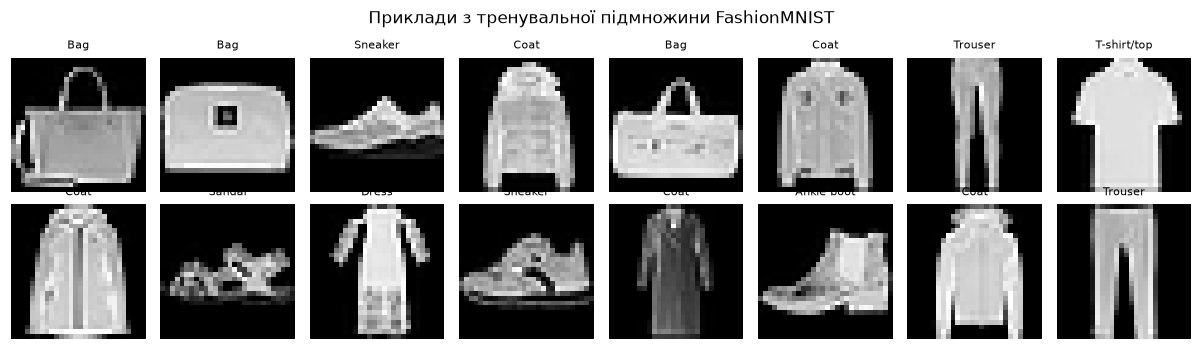

In [2]:
def load_fashion_mnist(cache_dir="data"):
    # Завантажує тренувальну частину FashionMNIST (idx-формат). Порядок спроб:
    # 1) локальний кеш / GitHub-репозиторій Zalando; 2) fetch_openml.
    base = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
    files = {"X": "train-images-idx3-ubyte.gz", "y": "train-labels-idx1-ubyte.gz"}
    os.makedirs(cache_dir, exist_ok=True)
    try:
        for name in files.values():
            path = os.path.join(cache_dir, name)
            if not os.path.exists(path):
                urllib.request.urlretrieve(base + name, path)
        with gzip.open(os.path.join(cache_dir, files["X"])) as f:
            X = np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 784)
        with gzip.open(os.path.join(cache_dir, files["y"])) as f:
            y = np.frombuffer(f.read(), np.uint8, offset=8)
        return X, y.astype(np.int64)
    except Exception as e:
        print("Пряме завантаження не вдалося (", e, "), пробуємо fetch_openml ...")
        from sklearn.datasets import fetch_openml
        d = fetch_openml("Fashion-MNIST", version=1, as_frame=False, parser="auto")
        return d.data.astype(np.uint8), d.target.astype(np.int64)

X_all, y_all = load_fashion_mnist()
rng_split = np.random.RandomState(SEED)
perm = rng_split.permutation(len(X_all))
tr_idx, va_idx = perm[:N_TRAIN], perm[N_TRAIN:N_TRAIN + N_VAL]
X_train = X_all[tr_idx].astype(np.float64) / 255.0
y_train = y_all[tr_idx]
X_val   = X_all[va_idx].astype(np.float64) / 255.0
y_val   = y_all[va_idx]
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print("train:", X_train.shape, "val:", X_val.shape, "| діапазон пікселів:", X_train.min(), "-", X_train.max())
print("розподіл класів (train):", np.bincount(y_train))

fig, axes = plt.subplots(2, 8, figsize=(11, 3.2))
for ax, i in zip(axes.ravel(), range(16)):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray"); ax.set_title(CLASS_NAMES[y_train[i]], fontsize=7); ax.axis("off")
plt.suptitle("Приклади з тренувальної підмножини FashionMNIST"); plt.tight_layout(); plt.show()

# Блок 1. Реалізація нейронної мережі з нуля

## 1.1 Архітектура мережі

* вхід: $784$ нейрони (вектор зображення $28\cdot28$, значення в $[0,1]$);
* **3 приховані шари**: $256 \to 128 \to 64$ нейронів, активація **ReLU**;
* вихід: $10$ нейронів (класи), активація **Softmax**;
* функція втрат: **categorical cross-entropy**;
* оптимізатор: **SGD** (мінібатчі, лінійне зменшення lr), початкова ініціалізація ваг — **He**, $W_{ij}\sim\mathcal N(0, 2/n_{in})$, зміщення ініціалізуються нулями.

Для кожного шару $Z^{(l)} = A^{(l-1)}W^{(l)} + b^{(l)}$, $A^{(l)} = f(Z^{(l)})$.

Клас `NeuralNetwork` зберігає матриці ваг, зміщення, проміжні $Z^{(l)}$ та $A^{(l)}$, параметри архітектури, а також реалізує прямий прохід (з опціональним inverted dropout), backpropagation (з опціональними L1/L2-градієнтами), діагностику мертвих нейронів та збереження/відновлення.

**Деталі реалізації**

* *Backprop.* Для Softmax + cross-entropy $\delta^{(L)} = (P - Y)/N$; для прихованих шарів $\delta^{(l)} = (\delta^{(l+1)} (W^{(l+1)})^T)\odot f'(Z^{(l)})$, $f'(z)=\mathbb 1[z>0]$; $\nabla_{W^{(l)}} = (A^{(l-1)})^T\delta^{(l)}$, $\nabla_{b^{(l)}} = \sum_i \delta^{(l)}_i$.
* *Dropout (inverted).* Після ReLU $\tilde A = A\odot M/(1-p)$, $M_i\sim\mathrm{Bernoulli}(1-p)$. У backward градієнт по $A$ множиться на ту саму маску $M/(1-p)$ *до* множення на $f'(Z)$. Під час оцінювання (inference) dropout вимкнений.
* *L1/L2.* Додаються до градієнта ваг: $\lambda_2 W$ та $\lambda_1\,\mathrm{sign}(W)$ (субградієнт у нулі дорівнює 0, `np.sign(0)=0`). Зміщення $b$ не регуляризуються.

In [3]:
class NeuralNetwork:
    # Повнозв'язна мережа (MLP): ReLU у прихованих шарах, Softmax на виході. Лише NumPy.

    def __init__(self, layer_sizes, init="he", dropout=0.0, seed=0, dtype=np.float64):
        self.layer_sizes = list(layer_sizes)
        self.init, self.dropout, self.seed, self.dtype = init, float(dropout), int(seed), np.dtype(dtype)
        self.num_layers = len(self.layer_sizes) - 1          # кількість матриць ваг
        rng = np.random.RandomState(seed)
        self.weights, self.biases = [], []
        for n_in, n_out in zip(self.layer_sizes[:-1], self.layer_sizes[1:]):
            if init == "he":                                  # N(0, 2/n_in)
                W = rng.randn(n_in, n_out) * np.sqrt(2.0 / n_in)
            elif init == "xavier":                            # U(-sqrt(6/(in+out)), +sqrt(6/(in+out)))
                lim = np.sqrt(6.0 / (n_in + n_out))
                W = rng.uniform(-lim, lim, size=(n_in, n_out))
            else:
                raise ValueError("init must be 'he' or 'xavier'")
            self.weights.append(W.astype(self.dtype))
            self.biases.append(np.zeros(n_out, dtype=self.dtype))
        self.mask_rng = np.random.RandomState(seed + 1)       # окремий генератор для масок dropout
        self.activations, self.z_values, self.masks = [], [], []

    # ------------------------- прямий прохід -------------------------
    def forward(self, X, training=False):
        # Повертає ймовірності класів. training=True вмикає dropout (лише для прихованих шарів).
        self.activations = [X]
        self.z_values, self.masks = [], []
        A = X
        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            Z = A @ W + b                                     # передактивація
            A = np.maximum(0, Z)                              # ReLU
            mask = None
            if training and self.dropout > 0:
                keep = 1.0 - self.dropout
                mask = (self.mask_rng.rand(*A.shape) < keep) / keep   # inverted dropout: M/(1-p)
                A = A * mask
            self.z_values.append(Z)                           # Z зберігаємо ДО dropout
            self.activations.append(A)                        # A (після dropout) — вхід наступного шару
            self.masks.append(mask)

        Z = A @ self.weights[-1] + self.biases[-1]
        Z = Z - np.max(Z, axis=1, keepdims=True)              # числова стабільність Softmax
        exp_Z = np.exp(Z)
        P = exp_Z / np.sum(exp_Z, axis=1, keepdims=True)
        self.z_values.append(Z)
        self.activations.append(P)
        return P

    # ------------------------- backpropagation -------------------------
    def backward(self, y_true, l1=0.0, l2=0.0):
        # Градієнти за всіма W та b. Якщо задано l1/l2 — додає градієнти регуляризаційних доданків.
        n = y_true.shape[0]
        grads_W = [None] * len(self.weights)
        grads_b = [None] * len(self.biases)

        # Softmax + cross-entropy: dL/dZ = (P - Y) / N
        delta = self.activations[-1].copy()
        delta[np.arange(n), y_true] -= 1
        delta /= n

        for l in reversed(range(len(self.weights))):
            A_prev = self.activations[l]
            gW = A_prev.T @ delta
            if l2:
                gW = gW + l2 * self.weights[l]                       # d/dW (lambda2/2 ||W||^2)
            if l1:
                gW = gW + l1 * np.sign(self.weights[l])              # субградієнт |W|, у 0 -> 0
            grads_W[l] = gW
            grads_b[l] = np.sum(delta, axis=0)

            if l > 0:
                delta = delta @ self.weights[l].T                    # dL/dA_{l-1}
                if self.masks[l - 1] is not None:
                    delta = delta * self.masks[l - 1]                # похідна dropout (маска вже з 1/(1-p))
                delta = delta * (self.z_values[l - 1] > 0)           # похідна ReLU
        return grads_W, grads_b

    # ------------------------- втрати та оцінка -------------------------
    @staticmethod
    def cross_entropy(P, y):
        return float(-np.mean(np.log(P[np.arange(len(y)), y] + 1e-12)))

    def reg_loss(self, l1=0.0, l2=0.0):
        r = 0.0
        if l1: r += l1 * sum(np.sum(np.abs(W)) for W in self.weights)
        if l2: r += 0.5 * l2 * sum(np.sum(W ** 2) for W in self.weights)
        return float(r)

    def total_loss(self, X, y, l1=0.0, l2=0.0):
        return self.cross_entropy(self.forward(X, training=False), y) + self.reg_loss(l1, l2)

    def predict_proba(self, X):
        return self.forward(X, training=False)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

    def evaluate(self, X, y, batch=5000):
        # (CE-loss, accuracy) в режимі inference (dropout вимкнено), без регуляризаційного доданка.
        losses, correct = 0.0, 0
        for i in range(0, len(X), batch):
            P = self.forward(X[i:i + batch], training=False)
            losses += self.cross_entropy(P, y[i:i + batch]) * len(P)
            correct += int(np.sum(np.argmax(P, axis=1) == y[i:i + batch]))
        return losses / len(X), correct / len(X)

    # ------------------------- діагностика нейронів -------------------------
    def neuron_stats(self, X):
        # Для кожного прихованого шару: max_i Z_ij та частка об'єктів, на яких нейрон активний (Z>0).
        # Dropout вимкнено (inference).
        self.forward(X, training=False)
        out = []
        for Z in self.z_values[:-1]:
            out.append({"max_z": Z.max(axis=0), "active_frac": (Z > 0).mean(axis=0)})
        return out

    def dead_neurons(self, X):
        # N_dead^(l) = sum_j I[max_i Z_ij <= 0] для кожного прихованого шару (inference).
        return [int(np.sum(s["max_z"] <= 0)) for s in self.neuron_stats(X)]

    # ------------------------- збереження / відновлення -------------------------
    def config(self):
        return {"layer_sizes": self.layer_sizes, "init": self.init, "dropout": self.dropout, "seed": self.seed,
                "dtype": str(self.dtype), "hidden_activation": "relu", "output_activation": "softmax",
                "loss": "categorical_cross_entropy"}

    def save_weights(self, path):
        data = {}
        for i, W in enumerate(self.weights):
            data[f"W_{i}"] = W
        for i, b in enumerate(self.biases):
            data[f"b_{i}"] = b
        data["layer_sizes"] = np.array(self.layer_sizes)           # архітектура
        data["config"] = np.array(json.dumps(self.config()))       # параметри ініціалізації та конфігурація
        np.savez(path, **data)

    def load_weights(self, path):
        data = np.load(path, allow_pickle=False)
        sizes = data["layer_sizes"].tolist()
        if sizes != self.layer_sizes:
            raise ValueError(f"Архітектура файлу {sizes} не збігається з архітектурою моделі {self.layer_sizes}")
        self.weights = [data[f"W_{i}"].copy() for i in range(self.num_layers)]
        self.biases  = [data[f"b_{i}"].copy() for i in range(self.num_layers)]
        return self

    @classmethod
    def from_file(cls, path):
        # Створює нову мережу за збереженою архітектурою/конфігурацією та завантажує ваги.
        data = np.load(path, allow_pickle=False)
        cfg = json.loads(str(data["config"]))
        net = cls(cfg["layer_sizes"], init=cfg["init"], dropout=cfg["dropout"], seed=cfg["seed"], dtype=np.dtype(cfg["dtype"]))
        return net.load_weights(path)

net = NeuralNetwork(LAYERS, init="he", seed=SEED)
print("Архітектура:", net.layer_sizes, "| кількість параметрів:", sum(W.size + b.size for W, b in zip(net.weights, net.biases)))
P0 = net.forward(X_train[:5])
print("Форма виходу:", P0.shape, "| суми ймовірностей:", P0.sum(axis=1).round(6))
for i, W in enumerate(net.weights[:-1]):
    print(f"шар {i+1}: std ваг = {W.std():.4f}, теоретично sqrt(2/n_in) = {np.sqrt(2/W.shape[0]):.4f}")

Архітектура: [784, 256, 128, 64, 10] | кількість параметрів: 242762
Форма виходу: (5, 10) | суми ймовірностей: [1. 1. 1. 1. 1.]
шар 1: std ваг = 0.0505, теоретично sqrt(2/n_in) = 0.0505
шар 2: std ваг = 0.0883, теоретично sqrt(2/n_in) = 0.0884
шар 3: std ваг = 0.1245, теоретично sqrt(2/n_in) = 0.1250


## 1.2 Перевірка правильності градієнтів (чисельне диференціювання)

Порівнюємо аналітичні градієнти з центральною різницею
$\dfrac{\partial L}{\partial\theta}\approx\dfrac{L(\theta+\varepsilon)-L(\theta-\varepsilon)}{2\varepsilon}$, $\varepsilon=10^{-5}$,
для випадково вибраних параметрів (по 5 ваг і 3 зміщення з кожного шару) на малому батчі. Відносна похибка
$E=\dfrac{|g_{analytic}-g_{numeric}|}{\max(10^{-8},\,|g_{analytic}|+|g_{numeric}|)}$.

Перевірка виконується двічі: (а) лише cross-entropy; (б) cross-entropy + L1 + L2 (перевірка градієнтів регуляризації). Dropout вимкнений (він випадковий, тому чисельна перевірка без фіксації маски не має сенсу), але backward з dropout використовує ту саму маску, що і forward, а множення на $M/(1-p)$ — лінійна операція. Для чистоти перевірки зміщенням задано невеликі випадкові значення.

In [4]:
def gradient_check(l1=0.0, l2=0.0, eps=1e-5, n_w=5, n_b=3, seed=0):
    rng = np.random.RandomState(seed)
    m = NeuralNetwork(LAYERS, init="he", seed=123, dtype=np.float64)
    m.biases = [rng.randn(*b.shape) * 0.1 for b in m.biases]
    idx = rng.choice(len(X_train), 16, replace=False)
    Xb, yb = X_train[idx], y_train[idx]

    m.forward(Xb, training=False)
    gW, gb = m.backward(yb, l1=l1, l2=l2)

    rows = []
    for l in range(m.num_layers):
        for kind, params, grads, n in (("W", m.weights, gW, n_w), ("b", m.biases, gb, n_b)):
            P = params[l]
            for _ in range(n):
                pos = tuple(rng.randint(0, s) for s in P.shape)
                old = P[pos]
                P[pos] = old + eps; Lp = m.total_loss(Xb, yb, l1, l2)
                P[pos] = old - eps; Lm = m.total_loss(Xb, yb, l1, l2)
                P[pos] = old
                g_num, g_an = (Lp - Lm) / (2 * eps), grads[l][pos]
                E = abs(g_an - g_num) / max(1e-8, abs(g_an) + abs(g_num))
                rows.append({"параметр": f"{kind}{l+1}{list(pos)}", "аналітичний": g_an, "чисельний": g_num, "відн. похибка E": E})
    return pd.DataFrame(rows)

for title, kw in (("(а) лише cross-entropy", {}), ("(б) CE + L1(1e-3) + L2(1e-3)", {"l1": 1e-3, "l2": 1e-3})):
    df_gc = gradient_check(**kw)
    print(f"{title}: max E = {df_gc['відн. похибка E'].max():.3e}, середня E = {df_gc['відн. похибка E'].mean():.3e}")
    assert df_gc["відн. похибка E"].max() < 1e-6, "градієнти не збігаються!"
display(gradient_check().sample(10, random_state=1).style.format({"аналітичний": "{:.6e}", "чисельний": "{:.6e}", "відн. похибка E": "{:.2e}"}))

(а) лише cross-entropy: max E = 9.807e-09, середня E = 1.389e-09
(б) CE + L1(1e-3) + L2(1e-3): max E = 5.943e-08, середня E = 1.470e-08


,параметр,аналітичний,чисельний,відн. похибка E
27,"W4[19, 5]",1.090011e-02,1.090011e-02,1.72e-11
3,"W1[219, 174]",0.000000e+00,0.000000e+00,0.00e+00
22,b3[24],3.026821e-03,3.026821e-03,1.81e-09
18,"W3[80, 60]",0.000000e+00,0.000000e+00,0.00e+00
23,b3[52],2.224759e-02,2.224759e-02,7.52e-11
17,"W3[25, 46]",-2.000343e-03,-2.000343e-03,4.91e-09
21,b3[58],-1.935134e-02,-1.935134e-02,2.23e-10
28,"W4[38, 6]",4.515626e-03,4.515626e-03,2.04e-09
19,"W3[75, 41]",0.000000e+00,0.000000e+00,0.00e+00
14,b2[6],2.547497e-02,2.547497e-02,3.40e-11


**Висновок.** Відносна похибка не перевищує $\sim10^{-7}$–$10^{-9}$ для всіх перевірених параметрів (для CE і для CE+L1+L2), тобто аналітичні градієнти з backpropagation коректні, зокрема врахування похідної ReLU, градієнтів вихідного шару Softmax+CE та регуляризаційних доданків.

## 1.3 Цикл навчання

`train()` реалізує повний цикл: перемішування тренувальних даних на початку кожної епохи → поділ на мінібатчі → прямий прохід → обчислення втрат → backward → оновлення $W^{(l)}\leftarrow W^{(l)}-\eta\nabla_{W^{(l)}}L$, $b^{(l)}\leftarrow b^{(l)}-\eta\nabla_{b^{(l)}}L$ → оцінка loss/accuracy на тренувальній і валідаційній вибірках у режимі inference.

Швидкість навчання $\eta$ лінійно зменшується від `LR=0.1` до `0.1·LR` протягом навчання (однаково для **всіх** експериментів): з постійним $\eta=0.1$ валідаційна метрика між епохами сильно коливалася, і порівняння методів за значенням останньої епохи було б шумним. Це все ще звичайний SGD (без momentum), лише з розкладом $\eta_t$.

Додаткові (необов'язкові) параметри для Блоку 2: `l1`, `l2` (штрафи), `weight_clip` (обмеження $W\in[-c,c]$ після кожного кроку), `grad_clip` (обрізання за **глобальною** L2-нормою всіх градієнтів: $g\leftarrow g\cdot\min(1, c/\|g\|_2)$). Dropout задається в конструкторі моделі. Без цих параметрів `train()` — звичайний SGD.

Метрики loss у графіках — це **cross-entropy без регуляризаційного доданка** (щоб значення були порівнянними між методами). Для графіків train loss/acc береться оцінка на всій тренувальній підмножині в режимі inference (без dropout).

In [5]:
def global_norm(arrays):
    return float(np.sqrt(sum(np.sum(a ** 2) for a in arrays)))

def train(model, X_tr, y_tr, X_va, y_va, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE,
          l1=0.0, l2=0.0, weight_clip=None, grad_clip=None, lr_final_frac=LR_FINAL_FRAC, shuffle_seed=SEED, verbose=False):
    rng = np.random.RandomState(shuffle_seed)                  # однакове перемішування для всіх експериментів
    hist = {k: [] for k in ("train_loss", "val_loss", "train_acc", "val_acc", "grad_norm_mean", "grad_norm_max", "clip_frac")}
    n = len(X_tr)
    for ep in range(1, epochs + 1):
        lr_ep = lr * (1.0 - (1.0 - lr_final_frac) * (ep - 1) / max(1, epochs - 1))   # лінійне зменшення lr
        order = rng.permutation(n)                             # 1. перемішування
        norms, clipped, steps = [], 0, 0
        for i in range(0, n, batch_size):                      # 2. мінібатчі
            idx = order[i:i + batch_size]
            xb, yb = X_tr[idx], y_tr[idx]
            model.forward(xb, training=True)                   # 3. прямий прохід (з dropout, якщо p>0)
            gW, gb = model.backward(yb, l1=l1, l2=l2)          # 5. зворотне поширення
            gnorm = global_norm(gW + gb)
            norms.append(gnorm)
            if grad_clip is not None and gnorm > grad_clip:    # gradient clipping за глобальною L2-нормою
                s = grad_clip / gnorm
                gW = [g * s for g in gW]; gb = [g * s for g in gb]
                clipped += 1
            for l in range(model.num_layers):                  # 6. SGD-оновлення
                model.weights[l] -= lr_ep * gW[l]
                model.biases[l]  -= lr_ep * gb[l]
                if weight_clip is not None:                    # weight clipping після кроку
                    np.clip(model.weights[l], -weight_clip, weight_clip, out=model.weights[l])
            steps += 1
        tl, ta = model.evaluate(X_tr, y_tr)                    # 4/7. loss і accuracy (inference)
        vl, va = model.evaluate(X_va, y_va)
        for k, v in zip(hist.keys(), (tl, vl, ta, va, np.mean(norms), np.max(norms), clipped / steps)):
            hist[k].append(float(v))
        if verbose and (ep == 1 or ep % 5 == 0 or ep == epochs):
            print(f"епоха {ep:3d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f} | ||g|| {np.mean(norms):.3f} | lr {lr_ep:.4f}")
        if not np.isfinite(tl):
            print("Розбіжність (NaN/inf) — навчання зупинено"); break
    return hist

## 1.4 Допоміжні функції аналізу та запуск експерименту

Для кожного експерименту (після навчання) обчислюються:

* **dead neurons** у кожному прихованому шарі за формулами (30)–(31): нейрон мертвий, якщо $\max_i Z^{(l)}_{ij}\le0$ на **всій тренувальній вибірці** (dropout вимкнено). Також рахуємо *«майже неактивні»* нейрони (активні менш ніж на 1 % об'єктів, але не мертві) та нейрони, мертві на train, але активні на валідації (щоб проілюструвати, що «мертвий на train» ≠ «мертвий у всьому просторі даних»);
* **sparsity** $S=\#\{|W_{ij}|<0.01\}/\#W_{ij}\cdot100\%$ — за вагами **прихованих шарів** (матриці $W^{(1)},W^{(2)},W^{(3)}$; для кожного шару окремо, а також для вихідного шару — у таблиці по шарах);
* кількість ваг на межах $\pm c$ (для weight clipping);
* loss/accuracy (train і val).

In [6]:
def sparsity(weight_list, thr=SPARSE_THR):
    # Частка ваг з |W| < thr, у відсотках.
    total = sum(W.size for W in weight_list)
    return 100.0 * sum(int(np.sum(np.abs(W) < thr)) for W in weight_list) / total

def hidden_weights_flat(model):
    return np.concatenate([W.ravel() for W in model.weights[:-1]])

def analyze(model, weight_clip=None):
    vl, va = model.evaluate(X_val, y_val)
    tl, ta = model.evaluate(X_train, y_train)
    st_tr, st_va = model.neuron_stats(X_train), None
    st_va = model.neuron_stats(X_val)
    n_neurons = LAYERS[1:-1]
    dead = [int(np.sum(s["max_z"] <= 0)) for s in st_tr]                                   # формула (30)
    rare = [int(np.sum((s["active_frac"] < 0.01) & (s["max_z"] > 0))) for s in st_tr]      # майже неактивні, але не мертві
    revived = [int(np.sum((s_tr["max_z"] <= 0) & (s_va["max_z"] > 0))) for s_tr, s_va in zip(st_tr, st_va)]
    at_bound = 0
    if weight_clip is not None:
        at_bound = int(sum(np.sum(np.abs(W) >= weight_clip - 1e-12) for W in model.weights[:-1]))
    return dict(
        train_loss=tl, train_acc=ta, val_loss=vl, val_acc=va,
        dead_per_layer=dead, neurons_per_layer=n_neurons,
        dead_pct_layer=[100.0 * d / n for d, n in zip(dead, n_neurons)],                    # формула (31)
        dead_pct=100.0 * sum(dead) / sum(n_neurons),
        rare_per_layer=rare, rare_pct=100.0 * sum(rare) / sum(n_neurons),
        revived_on_val=revived,
        sparsity_layers=[sparsity([W]) for W in model.weights],                             # по всіх 4 матрицях (остання — вихідний шар)
        sparsity=sparsity(model.weights[:-1]),                                              # за прихованими шарами
        at_bound=at_bound, max_abs_w=float(max(np.abs(W).max() for W in model.weights[:-1])),
        mean_abs_w=float(np.mean(np.abs(hidden_weights_flat(model)))),
    )

RESULTS = {}      # ім'я експерименту -> словник з моделлю, історією та метриками

def run_experiment(name, group, params, dropout=0.0, verbose=False, **train_kw):
    t0 = time.time()
    model = NeuralNetwork(LAYERS, init="he", dropout=dropout, seed=SEED)    # однакова початкова ініціалізація
    hist = train(model, X_train, y_train, X_val, y_val, verbose=verbose, **train_kw)
    m = analyze(model, weight_clip=train_kw.get("weight_clip"))
    RESULTS[name] = dict(name=name, group=group, params=params, model=model, history=hist, **m)
    print(f"[{name:<28}] val acc {m['val_acc']:.4f} | val loss {m['val_loss']:.4f} | dead {m['dead_pct']:5.2f}% | sparsity {m['sparsity']:5.2f}% | {time.time()-t0:.0f}s")
    return RESULTS[name]

# Початкова (He) ініціалізація — для порівняння розподілів ваг у розділі 4.2
init_model = NeuralNetwork(LAYERS, init="he", seed=SEED)
INIT_WEIGHTS = hidden_weights_flat(init_model).copy()
print("Початкова sparsity (He):", round(sparsity(init_model.weights[:-1]), 2), "%")

Початкова sparsity (He): 14.48 %


## 1.5 Навчання базової мережі та графіки навчання

Навчаємо мережу **без жодної регуляризації** (це одночасно базовий експеримент Блоку 2).

In [7]:
base = run_experiment("Без регуляризації", "baseline", "—", verbose=True, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE)

епоха   1 | train loss 1.0648 acc 0.6835 | val loss 1.0557 acc 0.6858 | ||g|| 2.046 | lr 0.1000
епоха   5 | train loss 0.4257 acc 0.8443 | val loss 0.4783 acc 0.8248 | ||g|| 1.398 | lr 0.0876
епоха  10 | train loss 0.4008 acc 0.8499 | val loss 0.4798 acc 0.8260 | ||g|| 1.384 | lr 0.0721
епоха  15 | train loss 0.3665 acc 0.8644 | val loss 0.4920 acc 0.8284 | ||g|| 1.393 | lr 0.0566
епоха  20 | train loss 0.2395 acc 0.9096 | val loss 0.3581 acc 0.8776 | ||g|| 1.357 | lr 0.0410
епоха  25 | train loss 0.2267 acc 0.9143 | val loss 0.3668 acc 0.8728 | ||g|| 1.326 | lr 0.0255
епоха  30 | train loss 0.1804 acc 0.9386 | val loss 0.3444 acc 0.8804 | ||g|| 1.273 | lr 0.0100
[Без регуляризації           ] val acc 0.8804 | val loss 0.3444 | dead  0.22% | sparsity 13.87% | 41s


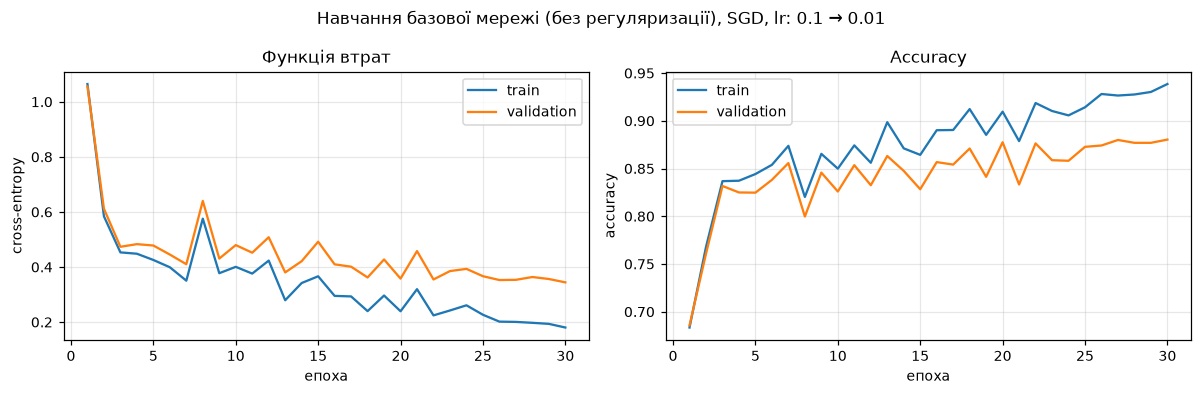

Фінально: train loss 0.1804, val loss 0.3444 | train acc 0.9386, val acc 0.8804
Мінімум val loss: 0.3444 на епосі 30


In [8]:
def plot_history(h, title):
    ep = np.arange(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot(ep, h["train_loss"], label="train"); ax[0].plot(ep, h["val_loss"], label="validation")
    ax[0].set(xlabel="епоха", ylabel="cross-entropy", title="Функція втрат"); ax[0].legend()
    ax[1].plot(ep, h["train_acc"], label="train"); ax[1].plot(ep, h["val_acc"], label="validation")
    ax[1].set(xlabel="епоха", ylabel="accuracy", title="Accuracy"); ax[1].legend()
    plt.suptitle(title); plt.tight_layout(); plt.show()

plot_history(base["history"], "Навчання базової мережі (без регуляризації), SGD, lr: %g → %g" % (LR, LR*LR_FINAL_FRAC))
h = base["history"]
print(f"Фінально: train loss {h['train_loss'][-1]:.4f}, val loss {h['val_loss'][-1]:.4f} | train acc {h['train_acc'][-1]:.4f}, val acc {h['val_acc'][-1]:.4f}")
print(f"Мінімум val loss: {min(h['val_loss']):.4f} на епосі {int(np.argmin(h['val_loss']))+1}")

**Пояснення до графіків.** Тренувальна та валідаційна втрати загалом зменшуються, accuracy зростає. У перші ~15 епох криві помітно «шумлять» через відносно великий крок lr (0.1 → 0.057), далі, коли lr зменшується, навчання стабілізується: фінально train acc ≈ **0.939**, val acc ≈ **0.880**, train loss 0.180, val loss 0.344. Розрив train–val (≈ 5.8 п.п.) вказує на помірне перенавчання: мережа запам'ятовує тренувальні дані краще, ніж узагальнює. Мінімум val loss досягається на останній епосі, тобто *зростання* val loss (класичний U-подібний вигляд) за 30 епох ще не настало, але розрив між кривими вже є — саме його намагаються зменшити методи регуляризації у Блоку 2.

## 1.6 Збереження та відновлення ваг

Зберігаємо у файл `.npz`: усі матриці ваг `W_i`, вектори зміщень `b_i`, архітектуру (`layer_sizes`) і конфігурацію (тип ініціалізації, seed, dropout, dtype, активації, функція втрат). Далі:

1. беремо навчену мережу, 2. зберігаємо ваги, 3. створюємо **новий** екземпляр з такою самою архітектурою (з *іншим* seed, тобто з іншими початковими вагами), 4. завантажуємо ваги, 5. подаємо однакові входи, 6. порівнюємо ймовірності та класи. Умова: $\max|P_{original}-P_{restored}|<10^{-7}$. Додатково перевіряємо відновлення «з нуля» одним викликом `NeuralNetwork.from_file()` (архітектура читається з файлу) та помилку при невідповідній архітектурі.

In [9]:
original = RESULTS["Без регуляризації"]["model"]
path = "fashion_mlp_baseline.npz"
original.save_weights(path)
print("Файл збережено:", path, "| розмір, КБ:", round(os.path.getsize(path) / 1024, 1))
print("Ключі у файлі:", sorted(np.load(path).files))
print("Конфігурація зі файлу:", json.loads(str(np.load(path)["config"])))

# новий екземпляр з тією самою архітектурою, але ІНШОЮ початковою ініціалізацією
restored = NeuralNetwork(LAYERS, init="he", seed=999)
P_before = restored.predict_proba(X_val)
P_orig = original.predict_proba(X_val)
print("\nДо завантаження: max|P_orig - P_new| =", f"{np.max(np.abs(P_orig - P_before)):.3e}", "(мережі різні)")

restored.load_weights(path)
P_rest = restored.predict_proba(X_val)
max_diff = np.max(np.abs(P_orig - P_rest))
same_cls = np.array_equal(original.predict(X_val), restored.predict(X_val))
print(f"Після завантаження: max|P_orig - P_restored| = {max_diff:.3e}  ->", "OK (< 1e-7)" if max_diff < 1e-7 else "ПОМИЛКА")
print("Передбачені класи збігаються для всіх", len(X_val), "об'єктів:", same_cls)
print("Val accuracy: оригінал =", round(original.evaluate(X_val, y_val)[1], 6), "| відновлена =", round(restored.evaluate(X_val, y_val)[1], 6))
assert max_diff < 1e-7 and same_cls

# відновлення «з нуля» (архітектура береться з файлу)
restored2 = NeuralNetwork.from_file(path)
print("from_file():", restored2.layer_sizes, "| max diff =", f"{np.max(np.abs(P_orig - restored2.predict_proba(X_val))):.3e}")

# захист від невідповідної архітектури
try:
    NeuralNetwork([784, 100, 10]).load_weights(path)
except ValueError as e:
    print("Очікувана помилка при іншій архітектурі:", e)

Файл збережено: fashion_mlp_baseline.npz | розмір, КБ: 1899.8
Ключі у файлі: ['W_0', 'W_1', 'W_2', 'W_3', 'b_0', 'b_1', 'b_2', 'b_3', 'config', 'layer_sizes']
Конфігурація зі файлу: {'layer_sizes': [784, 256, 128, 64, 10], 'init': 'he', 'dropout': 0.0, 'seed': 42, 'dtype': 'float64', 'hidden_activation': 'relu', 'output_activation': 'softmax', 'loss': 'categorical_cross_entropy'}

До завантаження: max|P_orig - P_new| = 9.988e-01 (мережі різні)
Після завантаження: max|P_orig - P_restored| = 0.000e+00  -> OK (< 1e-7)
Передбачені класи збігаються для всіх 5000 об'єктів: True
Val accuracy: оригінал = 0.8804 | відновлена = 0.8804
from_file(): [784, 256, 128, 64, 10] | max diff = 0.000e+00
Очікувана помилка при іншій архітектурі: Архітектура файлу [784, 256, 128, 64, 10] не збігається з архітектурою моделі [784, 100, 10]


**Висновок.** Нова мережа (створена з *іншою* початковою ініціалізацією, тому до завантаження її виходи відрізнялися від оригіналу майже на 1) після `load_weights` дає ймовірності, що збігаються з оригіналом із максимальною похибкою $0 < 10^{-7}$; передбачені класи збігаються для всіх 5000 валідаційних об'єктів, accuracy однакова. Це очікувано: `np.savez` зберігає `float64`-масиви без втрат, а обчислення детерміновані. Також перевірено відновлення «з нуля» через `NeuralNetwork.from_file()` (архітектура та конфігурація читаються з файлу) і захист від завантаження ваг в мережу з іншою архітектурою (`ValueError`). У файлі зберігаються: усі $W^{(l)}$, $b^{(l)}$, архітектура, тип ініціалізації, seed, dropout, dtype та типи активацій/втрат.

# Блок 2. Дослідження впливу регуляризації

Усі моделі мають одну архітектуру $784\to256\to128\to64\to10$, ReLU, He-ініціалізацію (однакові початкові ваги), SGD з `lr` від 0.1 до 0.01 (лінійно), мінібатч 128, 30 епох, однакові дані та порядок перемішування. Змінюється лише метод регуляризації. Значення гіперпараметрів (λ, p, c) наведені у кожному експерименті.

Допоміжні функції для таблиць:

In [10]:
def layer_table(names):
    # Таблиця dead neurons по прихованих шарах: «кількість / всього (відсоток)».
    rows = []
    for n in names:
        r = RESULTS[n]
        row = {"Експеримент": n}
        for i, (d, tot, p) in enumerate(zip(r["dead_per_layer"], r["neurons_per_layer"], r["dead_pct_layer"]), 1):
            row[f"Шар {i} ({tot})"] = f"{d}/{tot} ({p:.1f}%)"
        row["Разом dead, %"] = round(r["dead_pct"], 2)
        row["Майже неактивні (<1% об'єктів), %"] = round(r["rare_pct"], 2)
        row["Мертві на train, але активні на val"] = int(sum(r["revived_on_val"]))
        rows.append(row)
    return pd.DataFrame(rows).set_index("Експеримент")

def sparsity_table(names):
    rows = []
    for n in names:
        r = RESULTS[n]
        row = {"Експеримент": n}
        for i, s in enumerate(r["sparsity_layers"], 1):
            row[f"Sparsity W{i}, %" + (" (вихід)" if i == len(r["sparsity_layers"]) else "")] = round(s, 2)
        row["Sparsity (приховані), %"] = round(r["sparsity"], 2)
        row["mean |W|"] = round(r["mean_abs_w"], 4)
        row["max |W|"] = round(r["max_abs_w"], 3)
        row["ваг на межі ±c"] = r["at_bound"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("Експеримент")

def metrics_table(names):
    rows = []
    for n in names:
        r = RESULTS[n]
        rows.append({"Експеримент": n, "Параметри": r["params"], "Dead, %": round(r["dead_pct"], 2), "Sparsity, %": round(r["sparsity"], 2),
                     "Train acc": round(r["train_acc"], 4), "Val acc": round(r["val_acc"], 4),
                     "Train loss": round(r["train_loss"], 4), "Val loss": round(r["val_loss"], 4),
                     "Gap (train-val acc)": round(r["train_acc"] - r["val_acc"], 4)})
    return pd.DataFrame(rows).set_index("Експеримент")

def weight_stats_by_layer(model):
    rows = []
    for i, W in enumerate(model.weights, 1):
        rows.append({"Шар": f"W{i} {W.shape}" + (" (вихід)" if i == len(model.weights) else ""), "mean": W.mean(), "std": W.std(),
                     "min": W.min(), "max": W.max(), "частка |W|<0.01, %": 100 * np.mean(np.abs(W) < SPARSE_THR),
                     "частка |W|<0.001, %": 100 * np.mean(np.abs(W) < 1e-3)})
    return pd.DataFrame(rows).set_index("Шар").round(4)

def plot_hists(items, xlim=(-0.6, 0.6), bins=120, ncols=3, logy=True, ref=None, title=None, figw=11, rowh=2.6):
    # items: [(заголовок, масив ваг)]; ref=(мітка, масив) — контур для порівняння (напр. базова модель).
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(figw, rowh * nrows), squeeze=False)
    edges = np.linspace(xlim[0], xlim[1], bins + 1)
    for ax, (t, w) in zip(axes.ravel(), items):
        ax.hist(np.clip(w, xlim[0], xlim[1]), bins=edges, color="tab:blue", alpha=0.75)
        if ref is not None and t != ref[0]:
            ax.hist(np.clip(ref[1], xlim[0], xlim[1]), bins=edges, histtype="step", color="k", lw=0.9, label=ref[0])
            ax.legend(fontsize=6, loc="upper right")
        if logy: ax.set_yscale("log")
        ax.set_title(t, fontsize=8); ax.set_xlim(xlim)
    for ax in axes.ravel()[len(items):]: ax.axis("off")
    if title: plt.suptitle(title)
    plt.tight_layout(); plt.show()

## 3.1 Базовий експеримент (без регуляризації)

Базова модель вже навчена в п. 1.5. Фіксуємо фінальну валідаційну accuracy, значення функції втрат, кількість мертвих нейронів у кожному прихованому шарі, розподіл ваг кожного шару та частку майже нульових ваг ($|W|<0.01$).

Фінальна val accuracy : 0.8804
Фінальна val loss (CE): 0.3444   | train loss: 0.1804 | train acc: 0.9386
Dead neurons (усього) : 0.22% | sparsity (приховані): 13.87%

Статистика ваг по шарах (базова модель):


,mean,std,min,max,"частка |W|<0.01, %","частка |W|<0.001, %"
Шар,,,,,,
"W1 (784, 256)",-0.0002,0.0527,-0.2632,0.2438,15.0974,1.4569
"W2 (256, 128)",0.0015,0.0929,-0.4171,0.3547,8.3679,0.8698
"W3 (128, 64)",0.0031,0.1366,-0.5030,0.5134,5.8228,0.5859
"W4 (64, 10) (вихід)",0.0060,0.2687,-0.9723,0.8220,3.1250,0.4688


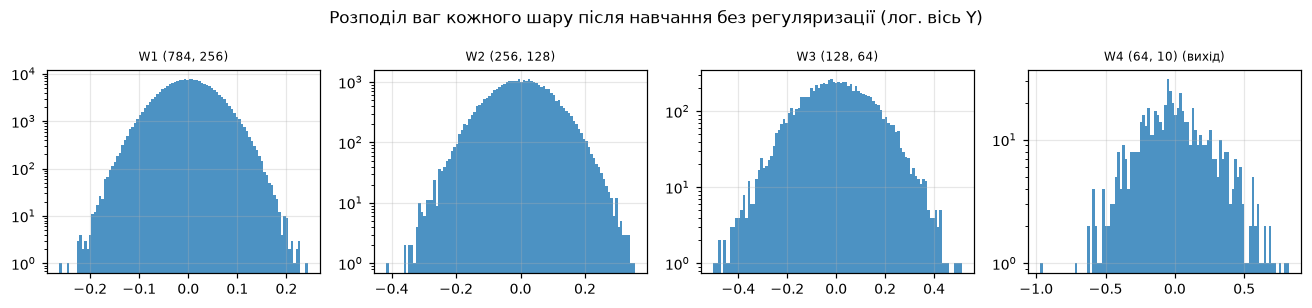

In [11]:
b = RESULTS["Без регуляризації"]
print(f"Фінальна val accuracy : {b['val_acc']:.4f}")
print(f"Фінальна val loss (CE): {b['val_loss']:.4f}   | train loss: {b['train_loss']:.4f} | train acc: {b['train_acc']:.4f}")
print(f"Dead neurons (усього) : {b['dead_pct']:.2f}% | sparsity (приховані): {b['sparsity']:.2f}%")
print("\nСтатистика ваг по шарах (базова модель):")
display(weight_stats_by_layer(b["model"]))

fig, axes = plt.subplots(1, 4, figsize=(12, 2.8))
for i, (ax, W) in enumerate(zip(axes, b["model"].weights), 1):
    ax.hist(W.ravel(), bins=100, color="tab:blue", alpha=0.8); ax.set_yscale("log")
    ax.set_title(f"W{i} {W.shape}" + (" (вихід)" if i == 4 else ""), fontsize=8)
plt.suptitle("Розподіл ваг кожного шару після навчання без регуляризації (лог. вісь Y)"); plt.tight_layout(); plt.show()

## 3.2 Діагностика мертвих нейронів

Нейрон вважається мертвим, якщо $\max_i Z^{(l)}_{ij}\le 0$ на **усій тренувальній вибірці** (формули 30–31). Діагностика виконується в режимі inference (`training=False`), тому dropout вимкнено і випадково вимкнені нейрони не можуть бути помилково віднесені до мертвих. Окремо вказано «майже неактивні» нейрони (активні менш ніж на 1 % об'єктів, але не мертві) та нейрони, які мертві на train, але активуються на валідації.

In [12]:
display(layer_table(["Без регуляризації"]))

,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Разом dead, %","Майже неактивні (<1% об'єктів), %","Мертві на train, але активні на val"
Експеримент,,,,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%),0.22,2.46,0


**Результати базового експерименту.** Val accuracy **0.8804**, val loss **0.3444** (train: 0.9386 / 0.1804). Мертвий лише **1 нейрон із 448** (0.22 %; шар 3: 1/64 ≈ 1.6 %), ще ≈2.5 % нейронів «майже неактивні» (активні менш ніж на 1 % об'єктів, але не мертві). Sparsity прихованих шарів 13.9 %: вона найбільша в першому шарі (15.1 %) і менша в наступних (8.4 %, 5.8 %). Це не наслідок «зникнення» ваг під час навчання: вже після He-ініціалізації sparsity становить 14.5 %, бо дисперсія ваг $2/n_{in}$ мала (std = 0.05 для першого шару), і порогу 0.01 відповідає близько 15 % ймовірнісної маси нормального розподілу. Тобто навчання розподіл ваг змінило слабко (max |W| ≈ 0.51). Важливий висновок для подальшого: **sparsity, виміряна за фіксованим порогом, залежить від масштабу ваг**, і базовий рівень 14 % — це «нуль відліку».

## 3.3 L2-регуляризація

$L=L_{CE}+\frac{\lambda_2}{2}\sum_l\|W^{(l)}\|_2^2$, оновлення $W\leftarrow W-\eta(\nabla_W L_{CE}+\lambda_2W)$ (реалізовано через `backward(..., l2=λ2)`). Досліджуємо $\lambda_2\in\{10^{-4},10^{-3},10^{-2}\}$.

[L2 (λ2=0.0001)              ] val acc 0.8820 | val loss 0.3396 | dead  0.22% | sparsity 14.21% | 36s
[L2 (λ2=0.001)               ] val acc 0.8822 | val loss 0.3392 | dead  0.45% | sparsity 17.68% | 40s
[L2 (λ2=0.01)                ] val acc 0.8560 | val loss 0.4312 | dead  2.90% | sparsity 73.18% | 50s


,Параметри,"Dead, %","Sparsity, %",Train acc,Val acc,Train loss,Val loss,Gap (train-val acc)
Експеримент,,,,,,,,
Без регуляризації,—,0.22,13.87,0.9386,0.8804,0.1804,0.3444,0.0582
L2 (λ2=0.0001),λ2=0.0001,0.22,14.21,0.9366,0.8820,0.1840,0.3396,0.0546
L2 (λ2=0.001),λ2=0.001,0.45,17.68,0.9259,0.8822,0.2150,0.3392,0.0437
L2 (λ2=0.01),λ2=0.01,2.90,73.18,0.8660,0.8560,0.3993,0.4312,0.0100


,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Разом dead, %","Майже неактивні (<1% об'єктів), %","Мертві на train, але активні на val"
Експеримент,,,,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%),0.22,2.46,0
L2 (λ2=0.0001),0/256 (0.0%),0/128 (0.0%),1/64 (1.6%),0.22,2.68,0
L2 (λ2=0.001),0/256 (0.0%),0/128 (0.0%),2/64 (3.1%),0.45,3.57,0
L2 (λ2=0.01),0/256 (0.0%),4/128 (3.1%),9/64 (14.1%),2.90,3.35,0


,"Sparsity W1, %","Sparsity W2, %","Sparsity W3, %","Sparsity W4, % (вихід)","Sparsity (приховані), %",mean |W|,max |W|,ваг на межі ±c
Експеримент,,,,,,,,
Без регуляризації,15.10,8.37,5.82,3.12,13.87,0.0486,0.513,0
L2 (λ2=0.0001),15.46,8.62,6.07,4.84,14.21,0.0474,0.517,0
L2 (λ2=0.001),19.24,10.66,7.46,4.84,17.68,0.0382,0.458,0
L2 (λ2=0.01),78.19,51.50,37.15,15.16,73.18,0.0085,0.309,0


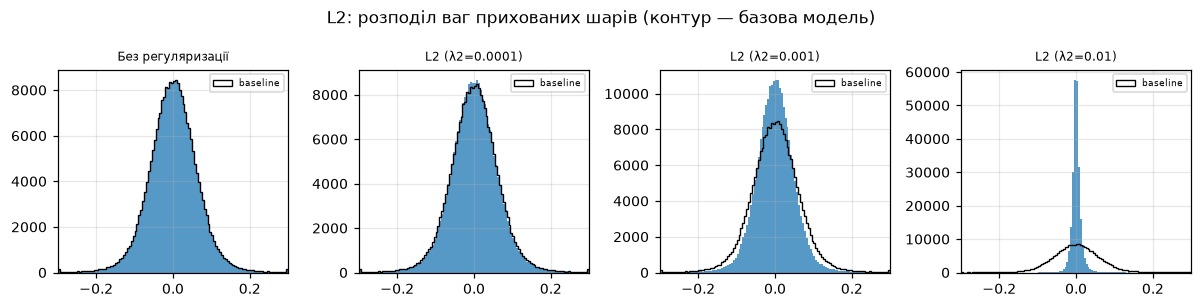

In [13]:
L2_VALUES = [1e-4, 1e-3, 1e-2]
for lam in L2_VALUES:
    run_experiment(f"L2 (λ2={lam:g})", "L2", f"λ2={lam:g}", l2=lam)
names = ["Без регуляризації"] + [f"L2 (λ2={l:g})" for l in L2_VALUES]
display(metrics_table(names)); display(layer_table(names)); display(sparsity_table(names))
plot_hists([(n, hidden_weights_flat(RESULTS[n]["model"])) for n in names], xlim=(-0.3, 0.3), bins=120, ncols=4, logy=False,
           ref=("baseline", hidden_weights_flat(b["model"])), title="L2: розподіл ваг прихованих шарів (контур — базова модель)", rowh=2.8)

**Аналіз L2.** Слабка L2 ($10^{-4}$, $10^{-3}$) практично не змінює точність (0.8820 і 0.8822 проти 0.8804 — різниця в межах статистичного шуму), але зменшує розрив train–val (5.8 → 5.5 → 4.4 п.п.) і зсуває ваги до нуля (mean |W|: 0.049 → 0.038), sparsity зростає 13.9 → 17.7 %. Сильна L2 ($10^{-2}$) дає mean |W| = 0.0085 і sparsity **73 %**, але водночас **знижує** val accuracy до 0.856 (train acc падає до 0.866 — це **недонавчання**, розрив майже зникає: 1 п.п.) і з'являються мертві нейрони (2.9 %, переважно в останньому прихованому шарі: 9/64 = 14 %). Показово, що L2 дає *багато малих, але не нульових ваг*: sparsity за порогом велика, хоча точних нулів немає. Кількість мертвих нейронів L2 зростає лише тоді, коли штраф настільки великий, що зміщення та ваги перестають підтримувати додатні передактивації.

## 3.4 L1-регуляризація

$L=L_{CE}+\lambda_1\sum_l\|W^{(l)}\|_1$, градієнт регуляризатора $\lambda_1\,\mathrm{sign}(W)$ з субградієнтом 0 у точці 0 (`np.sign(0)=0`). Досліджуємо $\lambda_1\in\{10^{-5},10^{-4},5\cdot10^{-4},2\cdot10^{-3}\}$. Важливо: при простому SGD (без proximal-оновлення) ваги не стають *точними* нулями, а «коливаються» біля нуля з амплітудою $\sim\eta\lambda_1$, тому sparsity вимірюється за порогом $|W|<0.01$.

[L1 (λ1=1e-05)               ] val acc 0.8820 | val loss 0.3426 | dead  0.22% | sparsity 17.08% | 49s
[L1 (λ1=0.0001)              ] val acc 0.8800 | val loss 0.3392 | dead  0.45% | sparsity 45.65% | 32s
[L1 (λ1=0.0005)              ] val acc 0.8546 | val loss 0.4201 | dead  2.01% | sparsity 93.43% | 39s
[L1 (λ1=0.002)               ] val acc 0.8226 | val loss 0.5079 | dead 28.35% | sparsity 99.55% | 34s


,Параметри,"Dead, %","Sparsity, %",Train acc,Val acc,Train loss,Val loss,Gap (train-val acc)
Експеримент,,,,,,,,
Без регуляризації,—,0.22,13.87,0.9386,0.8804,0.1804,0.3444,0.0582
L1 (λ1=1e-05),λ1=1e-05,0.22,17.08,0.9393,0.8820,0.1810,0.3426,0.0573
L1 (λ1=0.0001),λ1=0.0001,0.45,45.65,0.9224,0.8800,0.2240,0.3392,0.0424
L1 (λ1=0.0005),λ1=0.0005,2.01,93.43,0.8643,0.8546,0.3859,0.4201,0.0097
L1 (λ1=0.002),λ1=0.002,28.35,99.55,0.8305,0.8226,0.4856,0.5079,0.0079


,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Разом dead, %","Майже неактивні (<1% об'єктів), %","Мертві на train, але активні на val"
Експеримент,,,,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%),0.22,2.46,0
L1 (λ1=1e-05),0/256 (0.0%),0/128 (0.0%),1/64 (1.6%),0.22,2.90,0
L1 (λ1=0.0001),0/256 (0.0%),0/128 (0.0%),2/64 (3.1%),0.45,2.23,0
L1 (λ1=0.0005),1/256 (0.4%),2/128 (1.6%),6/64 (9.4%),2.01,2.01,0
L1 (λ1=0.002),87/256 (34.0%),28/128 (21.9%),12/64 (18.8%),28.35,0.00,0


,"Sparsity W1, %","Sparsity W2, %","Sparsity W3, %","Sparsity W4, % (вихід)","Sparsity (приховані), %",mean |W|,max |W|,ваг на межі ±c
Експеримент,,,,,,,,
Без регуляризації,15.10,8.37,5.82,3.12,13.87,0.0486,0.513,0
L1 (λ1=1e-05),18.62,10.16,7.18,4.06,17.08,0.0462,0.528,0
L1 (λ1=0.0001),49.44,29.00,19.47,10.00,45.65,0.0281,0.536,0
L1 (λ1=0.0005),96.29,82.90,65.52,35.78,93.43,0.0039,0.656,0
L1 (λ1=0.002),99.59,99.66,98.05,79.22,99.55,0.0006,1.579,0


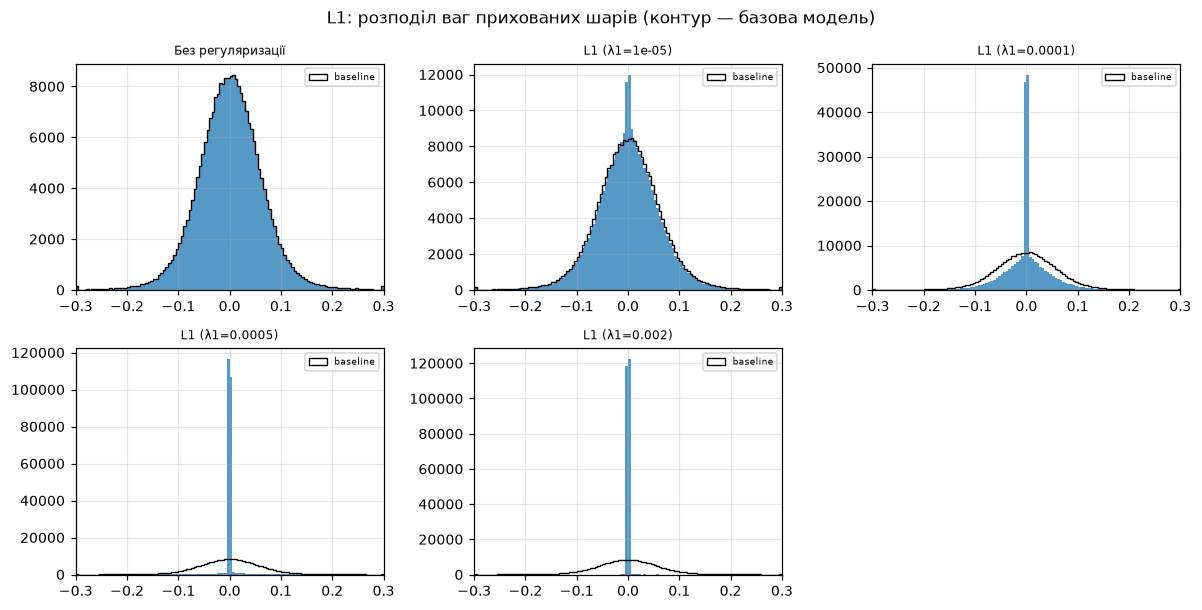

In [14]:
L1_VALUES = [1e-5, 1e-4, 5e-4, 2e-3]
for lam in L1_VALUES:
    run_experiment(f"L1 (λ1={lam:g})", "L1", f"λ1={lam:g}", l1=lam)
names = ["Без регуляризації"] + [f"L1 (λ1={l:g})" for l in L1_VALUES]
display(metrics_table(names)); display(layer_table(names)); display(sparsity_table(names))
plot_hists([(n, hidden_weights_flat(RESULTS[n]["model"])) for n in names], xlim=(-0.3, 0.3), bins=120, ncols=3, logy=False,
           ref=("baseline", hidden_weights_flat(b["model"])), title="L1: розподіл ваг прихованих шарів (контур — базова модель)", rowh=2.8)

**Аналіз L1.** L1 набагато ефективніше за L2 формує розріджені матриці: $\lambda_1=10^{-4}$ дає sparsity **45.7 %** (проти 17.7 % для L2 $10^{-3}$) при практично тій самій точності, що й базова модель (0.8800 vs 0.8804) і зі зменшенням розриву train–val до 4.2 п.п. Це найкращий компроміс «розрідженість/якість» серед усіх запусків. При $5\cdot10^{-4}$ sparsity 93 %, accuracy 0.8546, dead 2.0 %. При $2\cdot10^{-3}$ модель майже повністю «обнулена» (99.6 % ваг < 0.01), **28 % нейронів мертві** (у першому шарі 34 %), val accuracy 0.8226 — модель надмірно регуляризована; max |W| зростає до 1.58: кілька «вцілілих» ваг компенсують решту. Зауважимо, що з простим SGD ваги не стають точними нулями (немає proximal-кроку): вони коливаються біля нуля з амплітудою порядку $\eta\lambda_1$, тому sparsity вимірюється порогом 0.01. Із зростанням $\lambda_1$ зростають і sparsity, і dead neurons, але це **різні величини**: при $\lambda_1=10^{-4}$ sparsity 46 %, а dead лише 0.45 %.

## 3.5 Dropout

Inverted dropout у прихованих шарах: $\tilde A=A\odot M/(1-p)$, $M_i\sim\mathrm{Bernoulli}(1-p)$. Експерименти для $p\in\{0.1,0.3,0.5\}$; додатково $p=0.2$ (потрібен для порівняння з комбінацією L2 + Dropout у п. 3.8). Dead neurons і sparsity рахуються в режимі inference.

[Dropout 0.1                 ] val acc 0.8792 | val loss 0.3424 | dead  0.00% | sparsity 13.98% | 45s
[Dropout 0.3                 ] val acc 0.8712 | val loss 0.3634 | dead  0.00% | sparsity 13.94% | 40s
[Dropout 0.5                 ] val acc 0.8606 | val loss 0.4011 | dead  0.00% | sparsity 14.18% | 56s
[Dropout 0.2                 ] val acc 0.8764 | val loss 0.3512 | dead  0.00% | sparsity 13.95% | 76s


,Параметри,"Dead, %","Sparsity, %",Train acc,Val acc,Train loss,Val loss,Gap (train-val acc)
Експеримент,,,,,,,,
Без регуляризації,—,0.22,13.87,0.9386,0.8804,0.1804,0.3444,0.0582
Dropout 0.1,p=0.1,0.00,13.98,0.9241,0.8792,0.2107,0.3424,0.0449
Dropout 0.3,p=0.3,0.00,13.94,0.9058,0.8712,0.2606,0.3634,0.0346
Dropout 0.5,p=0.5,0.00,14.18,0.8764,0.8606,0.3414,0.4011,0.0158
Dropout 0.2,p=0.2,0.00,13.95,0.9155,0.8764,0.2347,0.3512,0.0391


,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Разом dead, %","Майже неактивні (<1% об'єктів), %","Мертві на train, але активні на val"
Експеримент,,,,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%),0.22,2.46,0
Dropout 0.1,0/256 (0.0%),0/128 (0.0%),0/64 (0.0%),0.00,3.79,0
Dropout 0.3,0/256 (0.0%),0/128 (0.0%),0/64 (0.0%),0.00,3.12,0
Dropout 0.5,0/256 (0.0%),0/128 (0.0%),0/64 (0.0%),0.00,7.59,0


,"Sparsity W1, %","Sparsity W2, %","Sparsity W3, %","Sparsity W4, % (вихід)","Sparsity (приховані), %",mean |W|,max |W|,ваг на межі ±c
Експеримент,,,,,,,,
Без регуляризації,15.10,8.37,5.82,3.12,13.87,0.0486,0.513,0
Dropout 0.1,15.18,8.53,6.31,2.81,13.98,0.0484,0.517,0
Dropout 0.3,15.12,8.65,6.27,2.81,13.94,0.0482,0.509,0
Dropout 0.5,15.37,8.80,6.45,2.34,14.18,0.0479,0.519,0


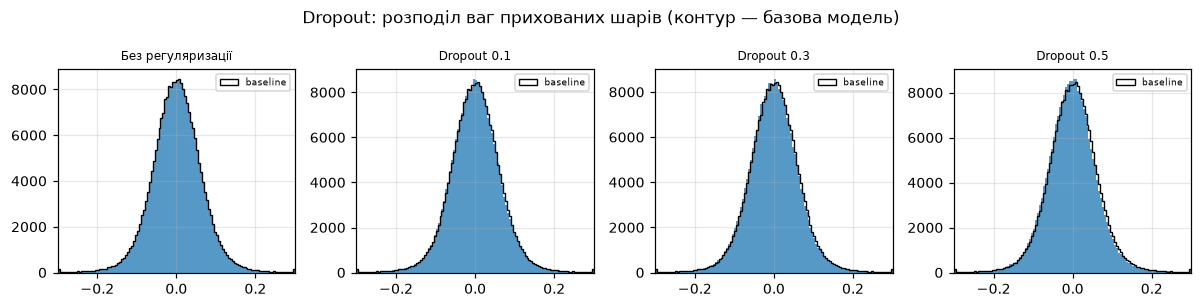

Dropout 0.5, діагностика у training-режимі на 2000 об'єктах: частка нейронів, що 'не активувались' ніколи = 0.26%
Dropout 0.5, діагностика в inference-режимі (правильно, на всій train-вибірці): dead = 0.00%


In [15]:
DROPOUT_VALUES = [0.1, 0.3, 0.5]
for p in DROPOUT_VALUES:
    run_experiment(f"Dropout {p}", "Dropout", f"p={p}", dropout=p)
run_experiment("Dropout 0.2", "Dropout", "p=0.2", dropout=0.2)

names = ["Без регуляризації"] + [f"Dropout {p}" for p in DROPOUT_VALUES]
display(metrics_table(names + ["Dropout 0.2"])); display(layer_table(names)); display(sparsity_table(names))
plot_hists([(n, hidden_weights_flat(RESULTS[n]["model"])) for n in names], xlim=(-0.3, 0.3), bins=120, ncols=4, logy=False,
           ref=("baseline", hidden_weights_flat(b["model"])), title="Dropout: розподіл ваг прихованих шарів (контур — базова модель)", rowh=2.8)

# Демонстрація: чому діагностику треба робити без dropout
m05 = RESULTS["Dropout 0.5"]["model"]
m05.forward(X_train[:2000], training=True)
zero_frac_train_mode = np.mean([(A == 0).all(axis=0).mean() for A in m05.activations[1:-1]])
print(f"Dropout 0.5, діагностика у training-режимі на 2000 об'єктах: частка нейронів, що 'не активувались' ніколи = {100*zero_frac_train_mode:.2f}%")
print(f"Dropout 0.5, діагностика в inference-режимі (правильно, на всій train-вибірці): dead = {RESULTS['Dropout 0.5']['dead_pct']:.2f}%")

**Аналіз Dropout.** Dropout змінює навчання, а не розподіл ваг: sparsity (13.9–14.2 %) і mean |W| (≈0.048) майже ідентичні базовим. Мертвих нейронів у режимі inference **немає** (0 %) для всіх $p$. Показова демонстрація в п. 3.5: якщо діагностувати Dropout 0.5 у *training*-режимі, то «ніколи не активні» виявляються 0.26 % нейронів, хоча справді мертвих 0 — випадково вимкнені маскою нейрони було б хибно віднесено до мертвих (тому діагностика ведеться з вимкненим Dropout). Точність: $p=0.1$ — 0.8792, $p=0.2$ — 0.8764, $p=0.3$ — 0.8712, $p=0.5$ — 0.8606, тобто **вона монотонно знижується** зі зростанням $p$ і не перевищує базову (0.8804). Розрив train–val при цьому швидко зменшується (4.5 → 3.9 → 3.5 → 1.6 п.п.), але переважно за рахунок падіння train accuracy (0.924 → 0.876). **Чому більше $p$ не завжди краще:** (1) високий $p$ додає в градієнти сильний шум і фактично зменшує ємність мережі в кожному кроці, що за фіксованих 30 епох призводить до недонавчання; (2) помірне перенавчання бази (≈6 п.п.) залишає мало «запасу» для покращення; (3) невідповідність статистик активацій між training (маска + масштабування $1/(1-p)$) та inference; (4) такі моделі зазвичай потребують довшого навчання. Також із $p=0.5$ зростає частка «майже неактивних» нейронів (7.6 % проти ≈2–4 %).

## 3.6 Weight clipping

Після кожного кроку SGD: $W^{(l)}\leftarrow\mathrm{clip}(W^{(l)},-1,1)$ (зміщення не обмежуються). Оскільки при He-ініціалізації та lr=0.1 ваги рідко досягають $\pm1$, додатково проведено **жорсткіший** експеримент із межею $\pm0.1$ — щоб побачити, що відбувається, коли обмеження реально «працює». Підраховуємо кількість ваг, що досягли меж.

[Weight clipping [-1,1]      ] val acc 0.8804 | val loss 0.3444 | dead  0.22% | sparsity 13.87% | 52s
[Weight clipping [-0.1,0.1]  ] val acc 0.8622 | val loss 0.3971 | dead  0.67% | sparsity 13.82% | 42s


,Параметри,"Dead, %","Sparsity, %",Train acc,Val acc,Train loss,Val loss,Gap (train-val acc)
Експеримент,,,,,,,,
Без регуляризації,—,0.22,13.87,0.9386,0.8804,0.1804,0.3444,0.0582
"Weight clipping [-1,1]",c=1,0.22,13.87,0.9386,0.8804,0.1804,0.3444,0.0582
"Weight clipping [-0.1,0.1]",c=0.1 (додатково),0.67,13.82,0.8797,0.8622,0.3434,0.3971,0.0175


,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Разом dead, %","Майже неактивні (<1% об'єктів), %","Мертві на train, але активні на val"
Експеримент,,,,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%),0.22,2.46,0
"Weight clipping [-1,1]",0/256 (0.0%),0/128 (0.0%),1/64 (1.6%),0.22,2.46,0
"Weight clipping [-0.1,0.1]",0/256 (0.0%),0/128 (0.0%),3/64 (4.7%),0.67,4.46,1


,"Sparsity W1, %","Sparsity W2, %","Sparsity W3, %","Sparsity W4, % (вихід)","Sparsity (приховані), %",mean |W|,max |W|,ваг на межі ±c
Експеримент,,,,,,,,
Без регуляризації,15.10,8.37,5.82,3.12,13.87,0.0486,0.513,0
"Weight clipping [-1,1]",15.10,8.37,5.82,3.12,13.87,0.0486,0.513,0
"Weight clipping [-0.1,0.1]",15.12,7.97,5.46,1.72,13.82,0.0446,0.100,1723


Weight clipping [-1,1]: ваг на межі ±1.0: 0 з 241664 (0.000%), max|W| = 0.5134
Weight clipping [-0.1,0.1]: ваг на межі ±0.1: 1723 з 241664 (0.713%), max|W| = 0.1000


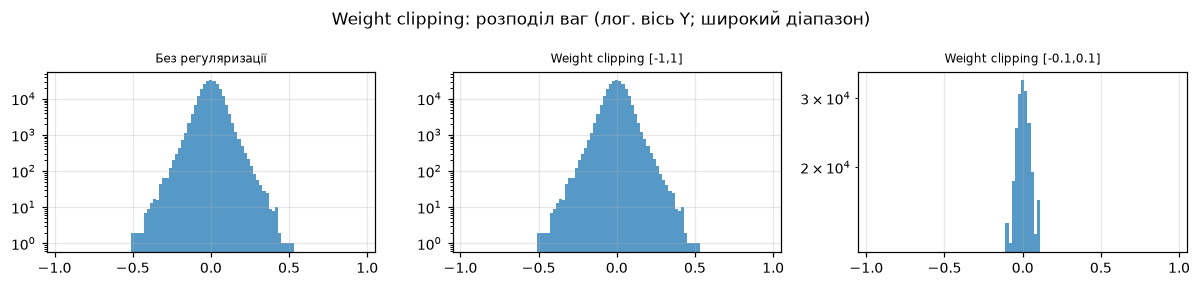

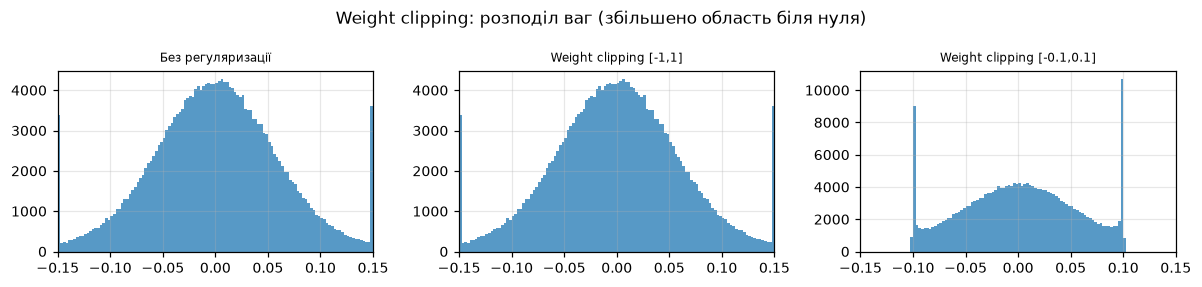

In [16]:
run_experiment("Weight clipping [-1,1]", "WeightClip", "c=1", weight_clip=1.0)
run_experiment("Weight clipping [-0.1,0.1]", "WeightClip", "c=0.1 (додатково)", weight_clip=0.1)
names = ["Без регуляризації", "Weight clipping [-1,1]", "Weight clipping [-0.1,0.1]"]
display(metrics_table(names)); display(layer_table(names)); display(sparsity_table(names))
for n, c in (("Weight clipping [-1,1]", 1.0), ("Weight clipping [-0.1,0.1]", 0.1)):
    w = hidden_weights_flat(RESULTS[n]["model"])
    print(f"{n}: ваг на межі ±{c}: {RESULTS[n]['at_bound']} з {w.size} ({100*RESULTS[n]['at_bound']/w.size:.3f}%), max|W| = {np.abs(w).max():.4f}")
plot_hists([("Без регуляризації", hidden_weights_flat(b["model"])), ("Weight clipping [-1,1]", hidden_weights_flat(RESULTS["Weight clipping [-1,1]"]["model"])),
            ("Weight clipping [-0.1,0.1]", hidden_weights_flat(RESULTS["Weight clipping [-0.1,0.1]"]["model"]))],
           xlim=(-1.05, 1.05), bins=105, ncols=3, logy=True, title="Weight clipping: розподіл ваг (лог. вісь Y; широкий діапазон)")
plot_hists([("Без регуляризації", hidden_weights_flat(b["model"])), ("Weight clipping [-1,1]", hidden_weights_flat(RESULTS["Weight clipping [-1,1]"]["model"])),
            ("Weight clipping [-0.1,0.1]", hidden_weights_flat(RESULTS["Weight clipping [-0.1,0.1]"]["model"]))],
           xlim=(-0.15, 0.15), bins=120, ncols=3, logy=False, title="Weight clipping: розподіл ваг (збільшено область біля нуля)")

**Аналіз weight clipping.** Межі $[-1,1]$ **не діють**: максимальна вага 0.51, жодної ваги на межі (0 з 241 664), тож результати збігаються з базовою моделлю побітово (0.8804; dead 0.22 %; sparsity 13.87 %). Тобто обмеження ±1 не є регуляризатором за такої ініціалізації та кроку навчання: воно «спрацювало б» лише при зростанні ваг. Для демонстрації справжнього ефекту проведено додатковий експеримент із межами $[-0.1,0.1]$: **1723 ваги (0.71 %)** опинилися точно на межах (на гістограмі видно піки при ±0.1), max |W| = 0.1, mean |W| знизилось до 0.0446, а точність упала до 0.8622 (train acc 0.880 — недонавчання), dead зріс до 0.67 %. Sparsity майже не змінилась (13.8 %), бо clipping обрізає лише «хвости», а не стягує ваги до нуля — на відміну від L1/L2. **Вплив жорсткого обмеження на оптимізацію:** це проєкція на гіперкуб; якщо оптимальні значення ваг лежать за межами куба, градієнт «упирається» в стінку, а ваги на межі втрачають можливість змінюватись у потрібному напрямку; модель змушена компенсувати цього іншими вагами, що обмежує виразність і призводить до гіршого мінімуму. У цьому експерименті один нейрон, мертвий на train, виявився активним на валідації (колонка «Мертві на train, але активні на val» у таблиці п. 3.6) — ілюстрація того, що «мертвий на тренувальній вибірці» ≠ «мертвий для всього простору даних».

## 3.7 Gradient clipping

Глобальна L2-норма всіх градієнтів $\|g\|_2=\sqrt{\sum_l(\|\nabla_{W^{(l)}}\|^2+\|\nabla_{b^{(l)}}\|^2)}$; якщо $\|g\|_2>c$, всі градієнти множаться на $c/\|g\|_2$ (формула 38). Спочатку подивимося на типову норму градієнтів без clipping, щоб обрати змістовні пороги $c$.

In [17]:
hb = b["history"]
print("Базова модель: середня норма градієнта по епохах (перші 3 / останні 3):", np.round(hb["grad_norm_mean"][:3], 3), np.round(hb["grad_norm_mean"][-3:], 3))
print("Максимальна норма градієнта за епохи (перші 3 / останні 3):", np.round(hb["grad_norm_max"][:3], 3), np.round(hb["grad_norm_max"][-3:], 3))

Базова модель: середня норма градієнта по епохах (перші 3 / останні 3): [2.046 1.652 1.572] [1.293 1.309 1.273]
Максимальна норма градієнта за епохи (перші 3 / останні 3): [4.172 3.676 2.768] [3.001 3.663 2.376]


[Gradient clipping (c=0.1)   ] val acc 0.8398 | val loss 0.4838 | dead  1.79% | sparsity 14.41% | 43s
[Gradient clipping (c=0.5)   ] val acc 0.8636 | val loss 0.4020 | dead  0.67% | sparsity 14.34% | 52s
[Gradient clipping (c=2)     ] val acc 0.8812 | val loss 0.3420 | dead  0.22% | sparsity 13.95% | 49s


,Параметри,"Dead, %","Sparsity, %",Train acc,Val acc,Train loss,Val loss,Gap (train-val acc)
Експеримент,,,,,,,,
Без регуляризації,—,0.22,13.87,0.9386,0.8804,0.1804,0.3444,0.0582
Gradient clipping (c=0.1),c=0.1,1.79,14.41,0.8411,0.8398,0.4640,0.4838,0.0013
Gradient clipping (c=0.5),c=0.5,0.67,14.34,0.8869,0.8636,0.3251,0.4020,0.0232
Gradient clipping (c=2),c=2,0.22,13.95,0.9378,0.8812,0.1816,0.3420,0.0566


,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Разом dead, %","Майже неактивні (<1% об'єктів), %","Мертві на train, але активні на val"
Експеримент,,,,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%),0.22,2.46,0
Gradient clipping (c=0.1),0/256 (0.0%),1/128 (0.8%),7/64 (10.9%),1.79,4.69,0
Gradient clipping (c=0.5),0/256 (0.0%),0/128 (0.0%),3/64 (4.7%),0.67,5.58,0
Gradient clipping (c=2),0/256 (0.0%),0/128 (0.0%),1/64 (1.6%),0.22,2.90,0


,"Sparsity W1, %","Sparsity W2, %","Sparsity W3, %","Sparsity W4, % (вихід)","Sparsity (приховані), %",mean |W|,max |W|,ваг на межі ±c
Експеримент,,,,,,,,
Без регуляризації,15.10,8.37,5.82,3.12,13.87,0.0486,0.513,0
Gradient clipping (c=0.1),15.70,8.57,6.01,4.84,14.41,0.0467,0.487,0
Gradient clipping (c=0.5),15.65,8.43,5.87,4.38,14.34,0.0471,0.472,0
Gradient clipping (c=2),15.19,8.46,5.55,4.22,13.95,0.0485,0.525,0


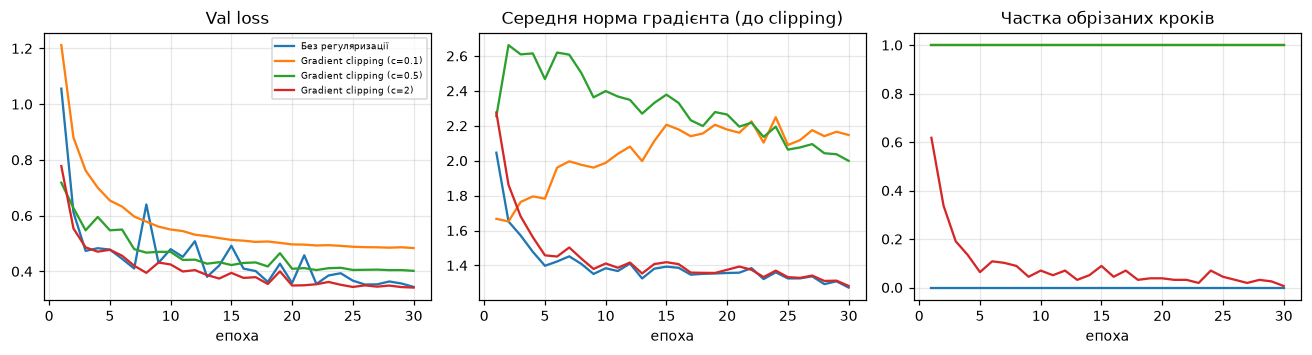

Стабільність: std від зміни val loss між сусідніми епохами (менше = плавніше):
  Без регуляризації                0.1125 | частка обрізаних кроків за всі епохи: 0.0%
  Gradient clipping (c=0.1)        0.0628 | частка обрізаних кроків за всі епохи: 100.0%
  Gradient clipping (c=0.5)        0.0310 | частка обрізаних кроків за всі епохи: 100.0%
  Gradient clipping (c=2)          0.0454 | частка обрізаних кроків за всі епохи: 8.6%


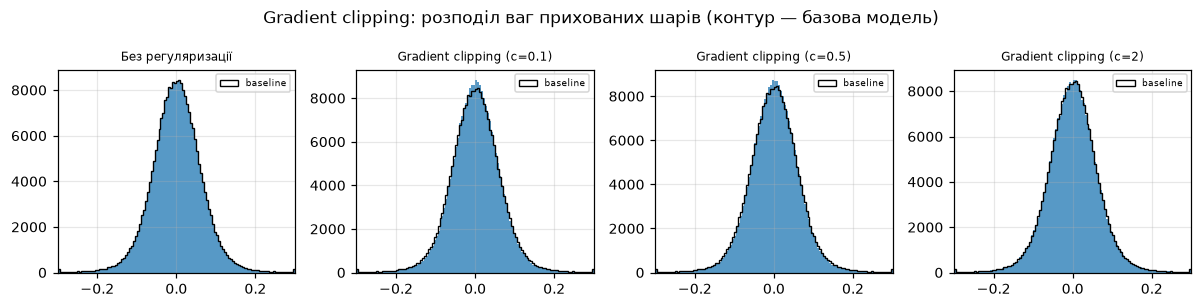

In [18]:
GC_VALUES = [0.1, 0.5, 2.0]
for c in GC_VALUES:
    run_experiment(f"Gradient clipping (c={c:g})", "GradClip", f"c={c:g}", grad_clip=c)
names = ["Без регуляризації"] + [f"Gradient clipping (c={c:g})" for c in GC_VALUES]
display(metrics_table(names)); display(layer_table(names)); display(sparsity_table(names))

fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for n in names:
    hh = RESULTS[n]["history"]; ep = np.arange(1, len(hh["val_loss"]) + 1)
    ax[0].plot(ep, hh["val_loss"], label=n); ax[1].plot(ep, hh["grad_norm_mean"], label=n); ax[2].plot(ep, hh["clip_frac"], label=n)
ax[0].set(title="Val loss", xlabel="епоха"); ax[1].set(title="Середня норма градієнта (до clipping)", xlabel="епоха"); ax[2].set(title="Частка обрізаних кроків", xlabel="епоха")
ax[0].legend(fontsize=6); plt.tight_layout(); plt.show()
print("Стабільність: std від зміни val loss між сусідніми епохами (менше = плавніше):")
for n in names:
    print(f"  {n:<32} {np.std(np.diff(RESULTS[n]['history']['val_loss'])):.4f} | частка обрізаних кроків за всі епохи: {100*np.mean(RESULTS[n]['history']['clip_frac']):.1f}%")
plot_hists([(n, hidden_weights_flat(RESULTS[n]["model"])) for n in names], xlim=(-0.3, 0.3), bins=120, ncols=4, logy=False,
           ref=("baseline", hidden_weights_flat(b["model"])), title="Gradient clipping: розподіл ваг прихованих шарів (контур — базова модель)", rowh=2.8)

**Аналіз gradient clipping.** Типова норма градієнта без clipping ≈ 1.3–2.0 (максимум ≈ 4). **$c=2$** обрізає лише 8.6 % кроків (найбільші викиди), дає ту саму точність, що й база (0.8812 vs 0.8804), але плавніші криві: стандартне відхилення зміни val loss між епохами 0.045 проти 0.113. **$c=0.5$ і $c=0.1$** обрізають 100 % кроків — це фактично нормований градієнт з довжиною кроку не більше $\eta c$; навчання сильно сповільнюється і виникає недонавчання (val acc 0.8636 та 0.8398, train acc 0.887 та 0.841), хоча крива loss найстабільніша (std 0.031 для $c=0.5$). Розподіл ваг при цьому змінюється мало (sparsity 13.9–14.4 %, mean |W| 0.047–0.0485): gradient clipping обмежує **кроки**, а не **значення ваг**, тому на відміну від weight clipping не створює піків на межах і не стискує хвости. Кількість мертвих нейронів при малих $c$ дещо зростає (0.67 % та 1.79 %, переважно в останньому шарі) — наш експеримент фіксує цей факт, але не встановлює його причину; про механізм можна лише висувати гіпотезу (повільніше навчання залишає частину нейронів у стані, де передактивація не додатна).

## 3.8 Комбінована регуляризація: L2 + Dropout ($p=0.2$)

$L=L_{CE}+\frac{\lambda_2}{2}\sum\|W\|_2^2$ разом із Dropout $p=0.2$. Беремо $\lambda_2=10^{-3}$ (одне зі значень із п. 3.3) і порівнюємо з відповідними окремими експериментами: L2 ($\lambda_2=10^{-3}$) та Dropout ($p=0.2$).

[L2 + Dropout 0.2            ] val acc 0.8736 | val loss 0.3484 | dead  0.00% | sparsity 17.76% | 45s


,Параметри,"Dead, %","Sparsity, %",Train acc,Val acc,Train loss,Val loss,Gap (train-val acc)
Експеримент,,,,,,,,
Без регуляризації,—,0.22,13.87,0.9386,0.8804,0.1804,0.3444,0.0582
L2 (λ2=0.001),λ2=0.001,0.45,17.68,0.9259,0.8822,0.2150,0.3392,0.0437
Dropout 0.2,p=0.2,0.00,13.95,0.9155,0.8764,0.2347,0.3512,0.0391
L2 + Dropout 0.2,"λ2=0.001, p=0.2",0.00,17.76,0.9121,0.8736,0.2490,0.3484,0.0385


,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Разом dead, %","Майже неактивні (<1% об'єктів), %","Мертві на train, але активні на val"
Експеримент,,,,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%),0.22,2.46,0
L2 (λ2=0.001),0/256 (0.0%),0/128 (0.0%),2/64 (3.1%),0.45,3.57,0
Dropout 0.2,0/256 (0.0%),0/128 (0.0%),0/64 (0.0%),0.00,2.23,0
L2 + Dropout 0.2,0/256 (0.0%),0/128 (0.0%),0/64 (0.0%),0.00,2.46,0


,"Sparsity W1, %","Sparsity W2, %","Sparsity W3, %","Sparsity W4, % (вихід)","Sparsity (приховані), %",mean |W|,max |W|,ваг на межі ±c
Експеримент,,,,,,,,
Без регуляризації,15.10,8.37,5.82,3.12,13.87,0.0486,0.513,0
L2 (λ2=0.001),19.24,10.66,7.46,4.84,17.68,0.0382,0.458,0
Dropout 0.2,15.14,8.52,6.56,2.81,13.95,0.0483,0.500,0
L2 + Dropout 0.2,19.28,10.96,7.68,3.75,17.76,0.0380,0.419,0


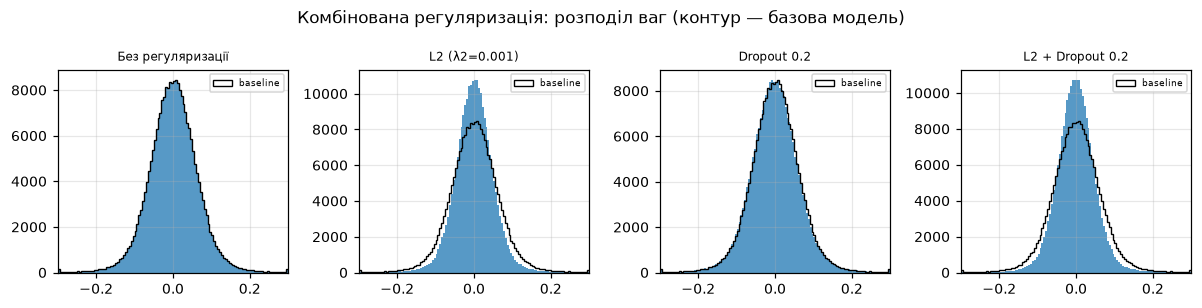

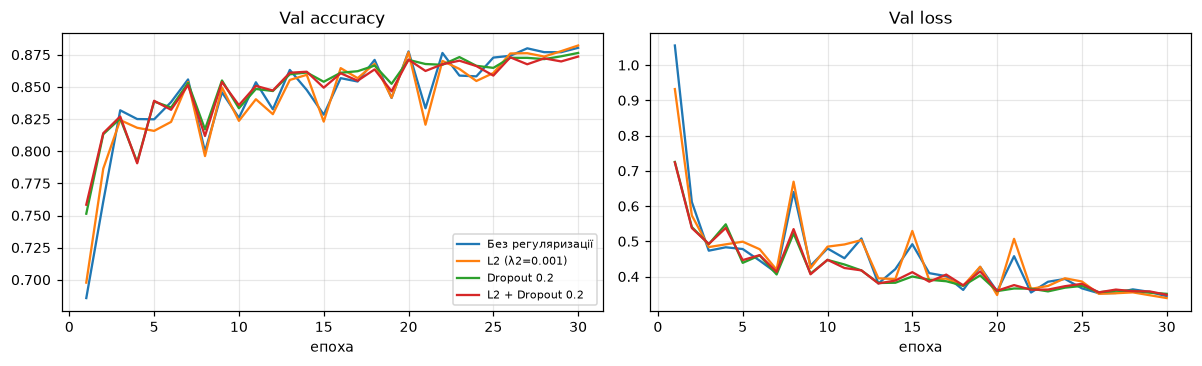

Δ val acc відносно L2 : -0.0086 | відносно Dropout 0.2: -0.0028 | відносно baseline: -0.0068
Dead: комбінація 0.00% | L2 0.45% | Dropout 0.00% | baseline 0.22%
Sparsity: комбінація 17.76% | L2 17.68% | Dropout 13.95% | baseline 13.87%


In [19]:
run_experiment("L2 + Dropout 0.2", "Combined", "λ2=0.001, p=0.2", l2=1e-3, dropout=0.2)
names = ["Без регуляризації", "L2 (λ2=0.001)", "Dropout 0.2", "L2 + Dropout 0.2"]
display(metrics_table(names)); display(layer_table(names)); display(sparsity_table(names))
plot_hists([(n, hidden_weights_flat(RESULTS[n]["model"])) for n in names], xlim=(-0.3, 0.3), bins=120, ncols=4, logy=False,
           ref=("baseline", hidden_weights_flat(b["model"])), title="Комбінована регуляризація: розподіл ваг (контур — базова модель)", rowh=2.8)

ep = np.arange(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for n in names:
    ax[0].plot(ep, RESULTS[n]["history"]["val_acc"], label=n); ax[1].plot(ep, RESULTS[n]["history"]["val_loss"], label=n)
ax[0].set(title="Val accuracy", xlabel="епоха"); ax[1].set(title="Val loss", xlabel="епоха"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

c, l2o, do = RESULTS["L2 + Dropout 0.2"], RESULTS["L2 (λ2=0.001)"], RESULTS["Dropout 0.2"]
print(f"Δ val acc відносно L2 : {c['val_acc']-l2o['val_acc']:+.4f} | відносно Dropout 0.2: {c['val_acc']-do['val_acc']:+.4f} | відносно baseline: {c['val_acc']-b['val_acc']:+.4f}")
print(f"Dead: комбінація {c['dead_pct']:.2f}% | L2 {l2o['dead_pct']:.2f}% | Dropout {do['dead_pct']:.2f}% | baseline {b['dead_pct']:.2f}%")
print(f"Sparsity: комбінація {c['sparsity']:.2f}% | L2 {l2o['sparsity']:.2f}% | Dropout {do['sparsity']:.2f}% | baseline {b['sparsity']:.2f}%")

**Аналіз комбінації L2 ($\lambda_2=10^{-3}$) + Dropout ($p=0.2$).** Результат: val acc **0.8736**, val loss 0.3484, dead 0 %, sparsity 17.76 %. Порівняння: baseline 0.8804, L2 окремо 0.8822, Dropout 0.2 окремо 0.8764. Отже:
* **Валідаційна точність не покращилась** — вона нижча за обидва окремі методи (−0.9 п.п. до L2, −0.3 п.п. до Dropout); частково це може бути шумом, але *виграшу* точно немає.
* **Мертві нейрони** зникли (0 %), як і в Dropout окремо (у L2 окремо — 0.45 %, у базі — 0.22 %); це різниця в один-два нейрони, тому робити з неї сильний висновок не варто.
* **Sparsity** (17.76 %) визначається L2-складовою (17.68 %); Dropout на неї не впливає.
* **Синергії немає.** Розрив train–val (3.85 п.п.) майже такий, як у Dropout 0.2 (3.9) і менший за L2 (4.4), але train acc знизилась до 0.912, і виграшу на валідації це не дало. Обидва методи борються з одним і тим самим помірним перенавчанням, тому їхні ефекти *перекриваються*, а сумарне обмеження починає знижувати ємність моделі — початок «надмірного обмеження».

# 4. Аналіз та порівняння результатів

## 4.1 Порівняльна таблиця

Для методів із налаштовуваними гіперпараметрами (L1, L2, gradient clipping) у компактній таблиці показано **найкраще за валідаційною accuracy** значення з перебраних (його вказано в колонці «Параметри»). Повна таблиця всіх запусків — нижче. *Примітка:* вибір гіперпараметра за тією самою валідаційною вибіркою, на якій звітуємо якість, дає невелике оптимістичне зміщення; для лабораторного порівняння це прийнятно, але для остаточної оцінки потрібна окрема тестова вибірка.

In [20]:
def best_of(group):
    cand = [n for n, r in RESULTS.items() if r["group"] == group]
    return max(cand, key=lambda n: RESULTS[n]["val_acc"])

MAIN = [("Без регуляризації", "Без регуляризації"),
        ("L1", best_of("L1")), ("L2", best_of("L2")),
        ("Dropout 0.1", "Dropout 0.1"), ("Dropout 0.3", "Dropout 0.3"), ("Dropout 0.5", "Dropout 0.5"),
        ("Weight clipping", "Weight clipping [-1,1]"), ("Gradient clipping", best_of("GradClip")),
        ("L2 + Dropout 0.2", "L2 + Dropout 0.2")]

rows = []
for label, key in MAIN:
    r = RESULTS[key]
    rows.append({"Метод": label, "Параметри": r["params"], "Dead neurons, %": round(r["dead_pct"], 2), "Sparsity, %": round(r["sparsity"], 2),
                 "Val. accuracy": round(r["val_acc"], 4), "Val. loss": round(r["val_loss"], 4)})
df_main = pd.DataFrame(rows).set_index("Метод")
display(Markdown("**Компактна порівняльна таблиця (вимога 4.1)**")); display(df_main)

display(Markdown("**Повна таблиця всіх експериментів**"))
df_all = metrics_table(list(RESULTS.keys()))
display(df_all)

**Компактна порівняльна таблиця (вимога 4.1)**

,Параметри,"Dead neurons, %","Sparsity, %",Val. accuracy,Val. loss
Метод,,,,,
Без регуляризації,—,0.22,13.87,0.8804,0.3444
L1,λ1=1e-05,0.22,17.08,0.8820,0.3426
L2,λ2=0.001,0.45,17.68,0.8822,0.3392
Dropout 0.1,p=0.1,0.00,13.98,0.8792,0.3424
Dropout 0.3,p=0.3,0.00,13.94,0.8712,0.3634
Dropout 0.5,p=0.5,0.00,14.18,0.8606,0.4011
Weight clipping,c=1,0.22,13.87,0.8804,0.3444
Gradient clipping,c=2,0.22,13.95,0.8812,0.3420
L2 + Dropout 0.2,"λ2=0.001, p=0.2",0.00,17.76,0.8736,0.3484


**Повна таблиця всіх експериментів**

,Параметри,"Dead, %","Sparsity, %",Train acc,Val acc,Train loss,Val loss,Gap (train-val acc)
Експеримент,,,,,,,,
Без регуляризації,—,0.22,13.87,0.9386,0.8804,0.1804,0.3444,0.0582
L2 (λ2=0.0001),λ2=0.0001,0.22,14.21,0.9366,0.8820,0.1840,0.3396,0.0546
L2 (λ2=0.001),λ2=0.001,0.45,17.68,0.9259,0.8822,0.2150,0.3392,0.0437
L2 (λ2=0.01),λ2=0.01,2.90,73.18,0.8660,0.8560,0.3993,0.4312,0.0100
L1 (λ1=1e-05),λ1=1e-05,0.22,17.08,0.9393,0.8820,0.1810,0.3426,0.0573
L1 (λ1=0.0001),λ1=0.0001,0.45,45.65,0.9224,0.8800,0.2240,0.3392,0.0424
L1 (λ1=0.0005),λ1=0.0005,2.01,93.43,0.8643,0.8546,0.3859,0.4201,0.0097
L1 (λ1=0.002),λ1=0.002,28.35,99.55,0.8305,0.8226,0.4856,0.5079,0.0079
Dropout 0.1,p=0.1,0.00,13.98,0.9241,0.8792,0.2107,0.3424,0.0449


In [21]:
display(Markdown("**Dead neurons у кожному прихованому шарі — усі експерименти**"))
display(layer_table(list(RESULTS.keys())))
display(Markdown("**Sparsity ваг по шарах — усі експерименти**"))
display(sparsity_table(list(RESULTS.keys())))

**Dead neurons у кожному прихованому шарі — усі експерименти**

,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Разом dead, %","Майже неактивні (<1% об'єктів), %","Мертві на train, але активні на val"
Експеримент,,,,,,
Без регуляризації,0/256 (0.0%),0/128 (0.0%),1/64 (1.6%),0.22,2.46,0
L2 (λ2=0.0001),0/256 (0.0%),0/128 (0.0%),1/64 (1.6%),0.22,2.68,0
L2 (λ2=0.001),0/256 (0.0%),0/128 (0.0%),2/64 (3.1%),0.45,3.57,0
L2 (λ2=0.01),0/256 (0.0%),4/128 (3.1%),9/64 (14.1%),2.90,3.35,0
L1 (λ1=1e-05),0/256 (0.0%),0/128 (0.0%),1/64 (1.6%),0.22,2.90,0
L1 (λ1=0.0001),0/256 (0.0%),0/128 (0.0%),2/64 (3.1%),0.45,2.23,0
L1 (λ1=0.0005),1/256 (0.4%),2/128 (1.6%),6/64 (9.4%),2.01,2.01,0
L1 (λ1=0.002),87/256 (34.0%),28/128 (21.9%),12/64 (18.8%),28.35,0.00,0
Dropout 0.1,0/256 (0.0%),0/128 (0.0%),0/64 (0.0%),0.00,3.79,0


**Sparsity ваг по шарах — усі експерименти**

,"Sparsity W1, %","Sparsity W2, %","Sparsity W3, %","Sparsity W4, % (вихід)","Sparsity (приховані), %",mean |W|,max |W|,ваг на межі ±c
Експеримент,,,,,,,,
Без регуляризації,15.10,8.37,5.82,3.12,13.87,0.0486,0.513,0
L2 (λ2=0.0001),15.46,8.62,6.07,4.84,14.21,0.0474,0.517,0
L2 (λ2=0.001),19.24,10.66,7.46,4.84,17.68,0.0382,0.458,0
L2 (λ2=0.01),78.19,51.50,37.15,15.16,73.18,0.0085,0.309,0
L1 (λ1=1e-05),18.62,10.16,7.18,4.06,17.08,0.0462,0.528,0
L1 (λ1=0.0001),49.44,29.00,19.47,10.00,45.65,0.0281,0.536,0
L1 (λ1=0.0005),96.29,82.90,65.52,35.78,93.43,0.0039,0.656,0
L1 (λ1=0.002),99.59,99.66,98.05,79.22,99.55,0.0006,1.579,0
Dropout 0.1,15.18,8.53,6.31,2.81,13.98,0.0484,0.517,0


**Висновки з таблиць.**
* У компактній таблиці всі методи лежать у вузькому діапазоні accuracy **0.861–0.882**. Найкращі (L2 $10^{-3}$: 0.8822; L1 $10^{-5}$: 0.8820; gradient clipping $c=2$: 0.8812) відрізняються від бази (0.8804) на 0.1–0.2 п.п. **Це в межах шуму**: стандартна похибка оцінки accuracy на 5000 об'єктах ≈ 0.46 п.п., а ми маємо один seed. Надійно можна стверджувати тільки про відмінності на рівні ≳1 п.п. — тобто що сильна регуляризація (Dropout 0.5, L1 $2\cdot10^{-3}$, жорсткий clipping, gradient clipping $c\le0.5$) якість **погіршує**.
* Dead neurons: у більшості запусків 0–0.7 %; помітні значення (>1.5 %) лише за сильної регуляризації: L2 $10^{-2}$ (2.9 %), L1 $5\cdot10^{-4}$ (2.0 %), L1 $2\cdot10^{-3}$ (**28.4 %**), gradient clipping $c=0.1$ (1.8 %). Dropout мертвих нейронів не створює.
* Sparsity: суттєво змінюють її лише L1 (до 99.6 %) та L2 (до 73 %); Dropout, clipping ±1 і gradient clipping залишають її на рівні ≈14 %.
* Мертві нейрони в кожному шарі (таблиця вище): мертві нейрони зазвичай концентруються в останньому (найвужчому) прихованому шарі (напр. L2 $10^{-2}$: 14 % у шарі 3 проти 0 % у шарі 1); виняток — L1 $2\cdot10^{-3}$, де «обнулено» перший шар (34 %).

## 4.2 Розподіл ваг

Гістограми ваг усіх прихованих шарів ($W^{(1)},W^{(2)},W^{(3)}$ разом): початковий розподіл (He), розподіл після навчання без регуляризації та після кожного методу (для методів із кількома значеннями гіперпараметра — найкраще значення з компактної таблиці). Вісь Y — логарифмічна, щоб були видні «хвости» та піки біля меж $\pm1$.

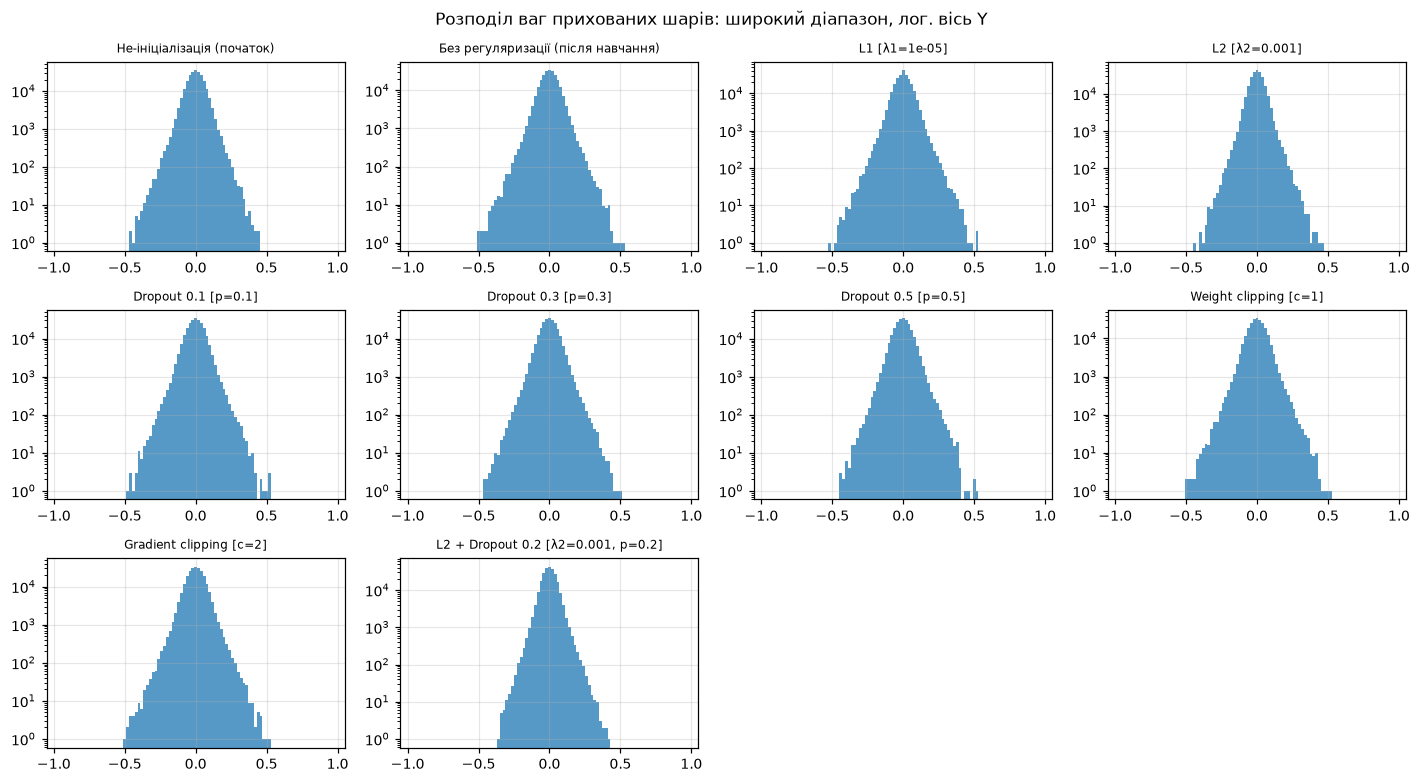

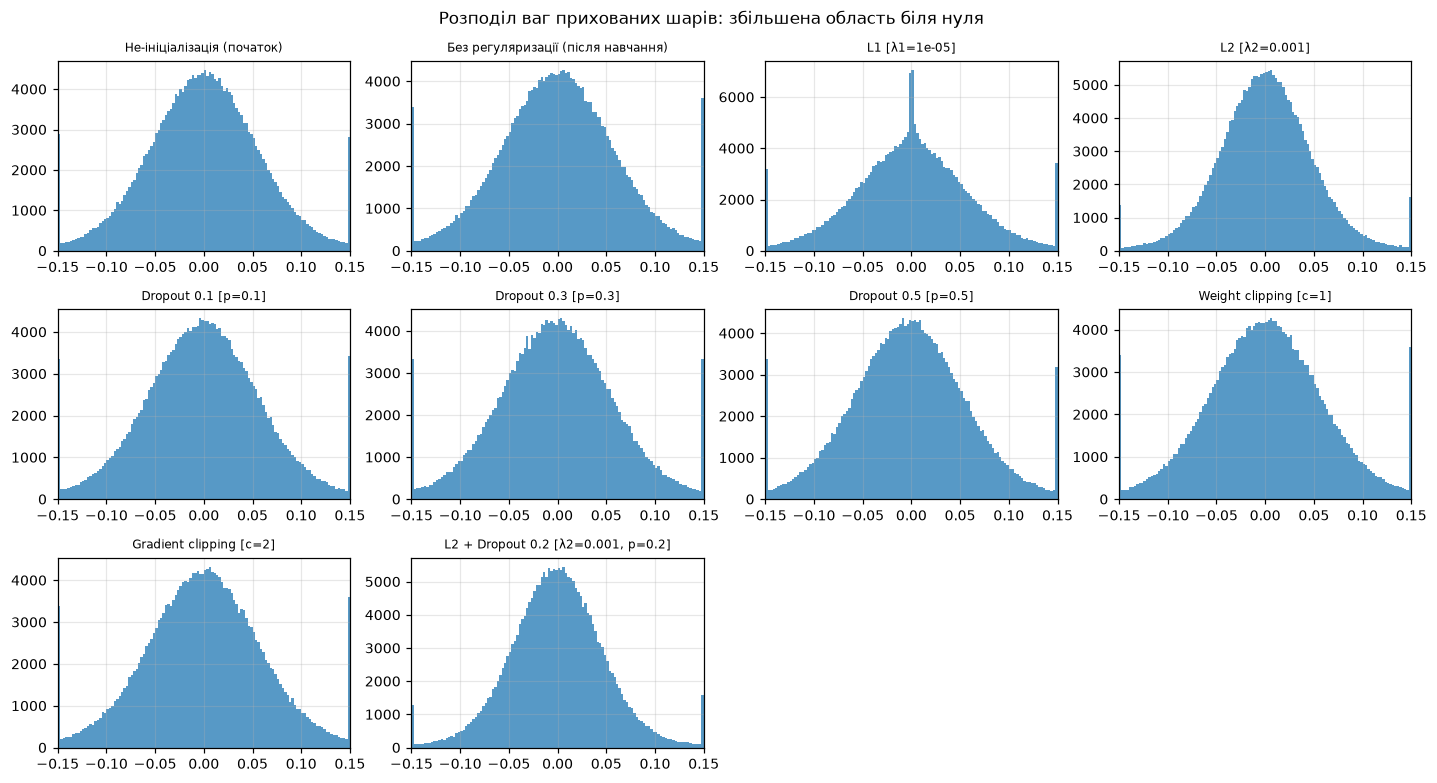

,mean,std,mean |W|,max |W|,"|W|<0.01, %","|W|<0.001, %","|W|>=0.99, шт."
Розподіл,,,,,,,
He-ініціалізація (початок),-0.0000,0.0608,0.0464,0.4529,14.4767,1.4541,0
Без регуляризації (після навчання),0.0001,0.0641,0.0486,0.5134,13.8705,1.3477,0
L1 [λ1=1e-05],0.0001,0.0623,0.0462,0.5279,17.0836,3.1291,0
L2 [λ2=0.001],0.0004,0.0506,0.0382,0.4581,17.6807,1.7855,0
Dropout 0.1 [p=0.1],-0.0007,0.0637,0.0484,0.5172,13.9789,1.3862,0
Dropout 0.3 [p=0.3],-0.0015,0.0634,0.0482,0.5087,13.9433,1.4015,0
Dropout 0.5 [p=0.5],-0.0025,0.0629,0.0479,0.5193,14.1779,1.4090,0
Weight clipping [c=1],0.0001,0.0641,0.0486,0.5134,13.8705,1.3477,0
Gradient clipping [c=2],0.0002,0.0640,0.0485,0.5248,13.9471,1.4148,0


In [22]:
items = [("He-ініціалізація (початок)", INIT_WEIGHTS), ("Без регуляризації (після навчання)", hidden_weights_flat(b["model"]))]
for label, key in MAIN[1:]:
    items.append((f"{label} [{RESULTS[key]['params']}]", hidden_weights_flat(RESULTS[key]["model"])))
plot_hists(items, xlim=(-1.05, 1.05), bins=105, ncols=4, logy=True, title="Розподіл ваг прихованих шарів: широкий діапазон, лог. вісь Y", figw=13, rowh=2.4)
plot_hists(items, xlim=(-0.15, 0.15), bins=120, ncols=4, logy=False, title="Розподіл ваг прихованих шарів: збільшена область біля нуля", figw=13, rowh=2.4)

stat_rows = []
for label, w in items:
    stat_rows.append({"Розподіл": label, "mean": w.mean(), "std": w.std(), "mean |W|": np.abs(w).mean(), "max |W|": np.abs(w).max(),
                      "|W|<0.01, %": 100*np.mean(np.abs(w) < 0.01), "|W|<0.001, %": 100*np.mean(np.abs(w) < 0.001), "|W|>=0.99, шт.": int(np.sum(np.abs(w) >= 0.99))})
display(pd.DataFrame(stat_rows).set_index("Розподіл").round(4))

Додатково — порівняння різних значень гіперпараметрів для методів, що впливають на розподіл ваг найсильніше (L1 і L2; контур — базова модель):

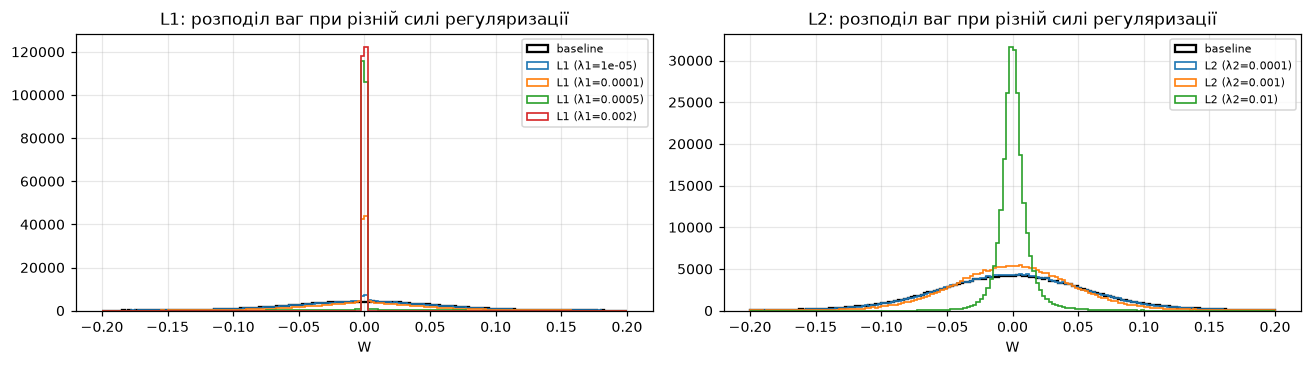

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
edges = np.linspace(-0.2, 0.2, 161)
for a, grp, vals, fmt in ((ax[0], "L1", L1_VALUES, "L1 (λ1={:g})"), (ax[1], "L2", L2_VALUES, "L2 (λ2={:g})")):
    a.hist(hidden_weights_flat(b["model"]), bins=edges, histtype="step", color="k", lw=1.5, label="baseline")
    for v in vals:
        a.hist(hidden_weights_flat(RESULTS[fmt.format(v)]["model"]), bins=edges, histtype="step", lw=1.1, label=fmt.format(v))
    a.set_title(f"{grp}: розподіл ваг при різній силі регуляризації"); a.set_xlabel("W"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Висновки з гістограм.** Початковий (He) і навчений без регуляризації розподіли — майже однакові «дзвони» навколо нуля (std шарів 0.05/0.09/0.12): SGD за 30 епох лише злегка змінює ваги (max |W| ≈ 0.51), і sparsity 14.5 % → 13.9 %. **L2** звужує розподіл і підвищує центральний пік (mean |W| 0.049 → 0.038 для $10^{-3}$ і 0.0085 для $10^{-2}$), але без «гострого» піку в точному нулі. **L1** створює різкий пік біля нуля та водночас зберігає «хвости» (max |W| ≈ 0.54 для $10^{-4}$ і 1.58 для $2\cdot10^{-3}$): частина ваг майже обнуляється, а кілька важливих зростають. **Dropout, gradient clipping та weight clipping $[-1,1]$** майже не змінюють розподіл ваг (для ±1 вони взагалі збігаються з базою, на межах ±1 піків немає: 0 ваг). Піки на межах з'являються лише при жорсткому $[-0.1,0.1]$ (1723 ваги на межі). Кількість ваг, близьких до нуля, збільшується тільки при L1/L2.

## 4.3 Залежність мертвих нейронів від точності

Діаграма розсіювання: вісь $x$ — відсоток мертвих нейронів, вісь $y$ — валідаційна accuracy, кожна точка — окремий експеримент (усі запуски, включно з різними значеннями гіперпараметрів). Праворуч — допоміжні залежності: sparsity ↔ accuracy та sparsity ↔ dead neurons (для аналізу пункту 4 «баланс між sparsity і мертвими нейронами»). Кольором позначено групу методів.

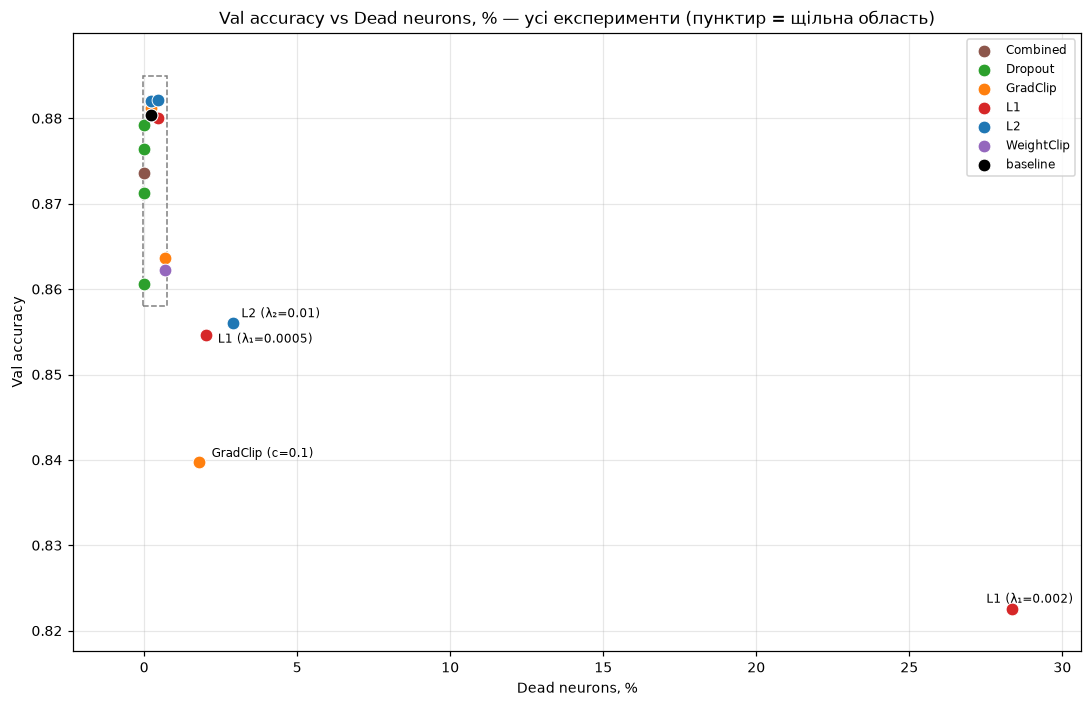

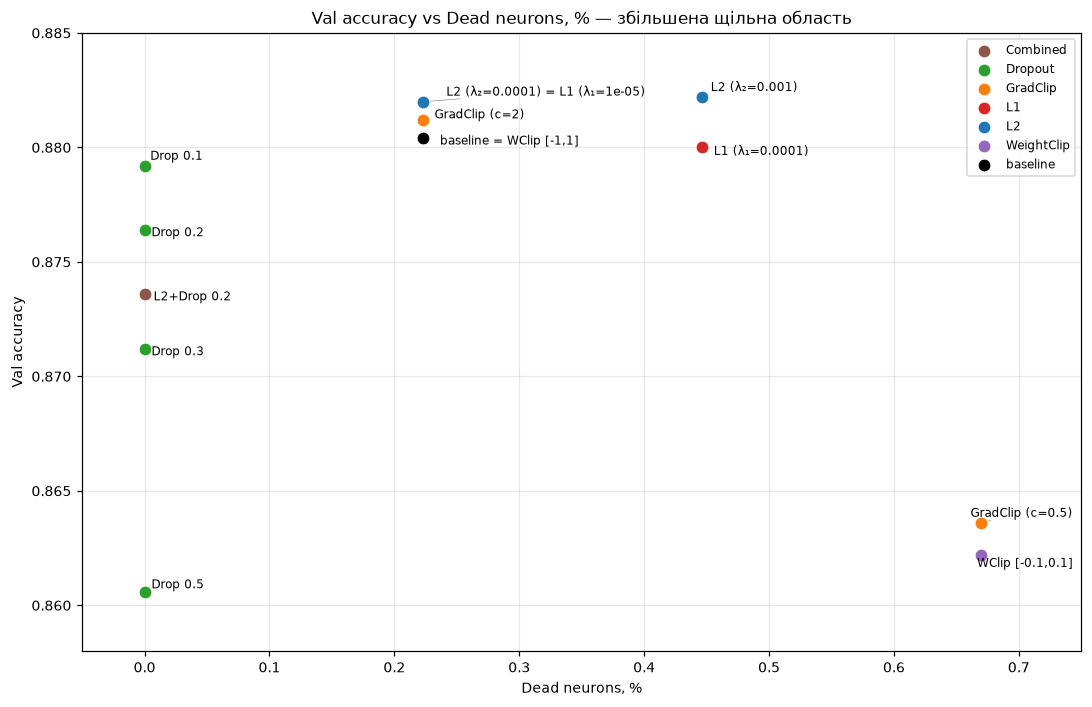

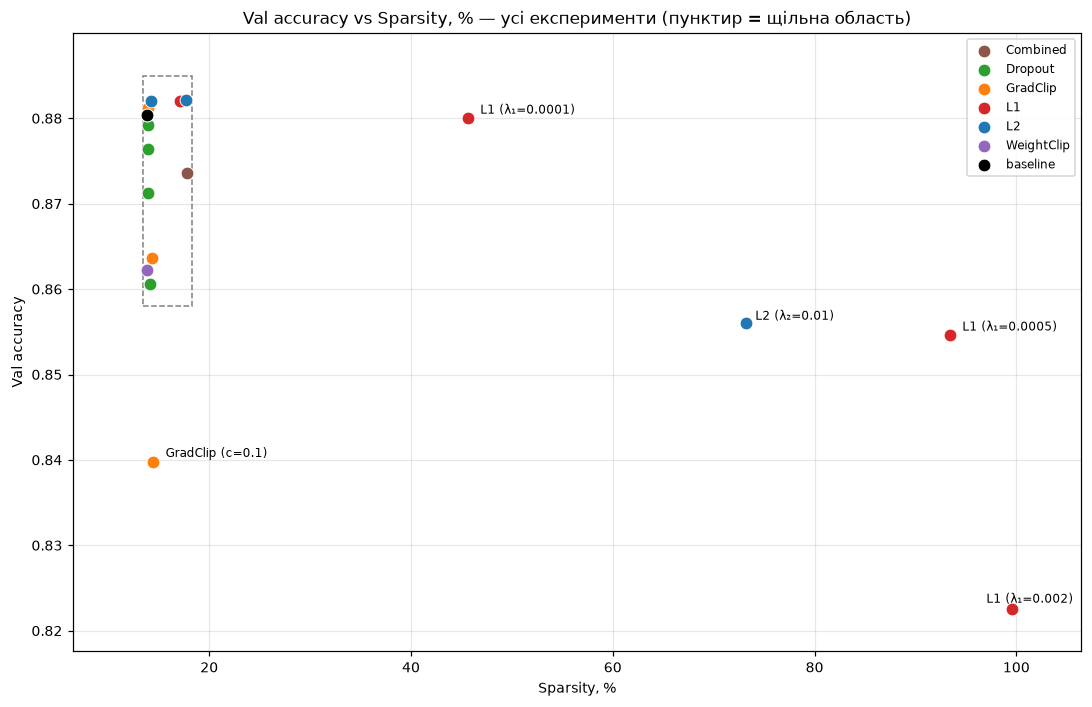

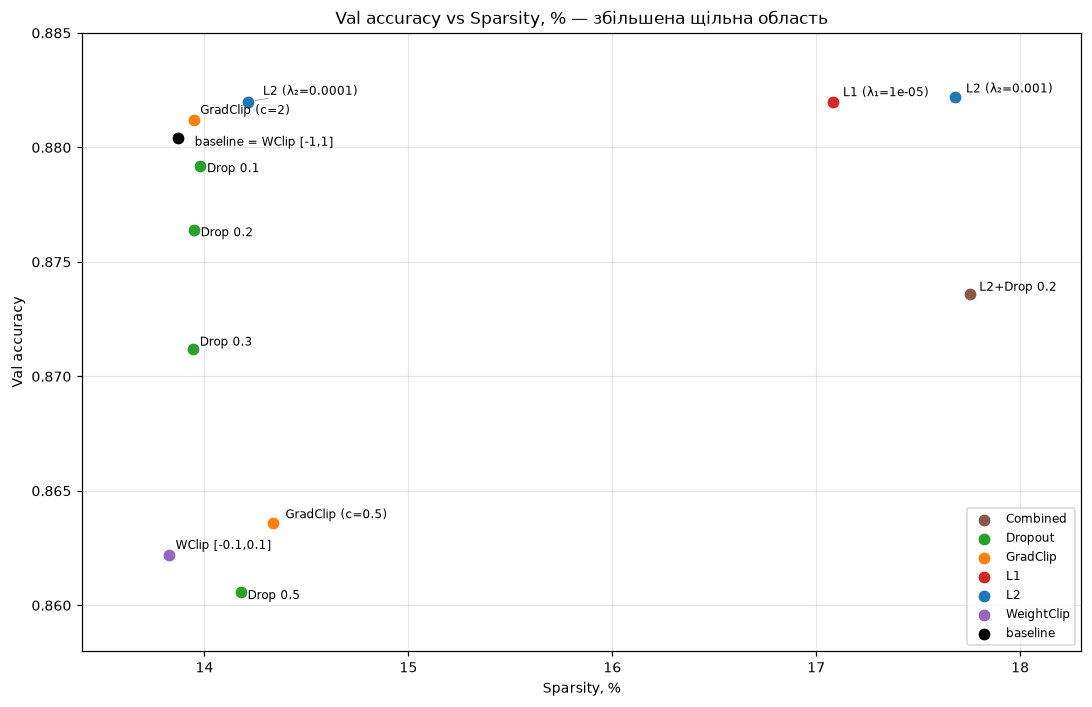

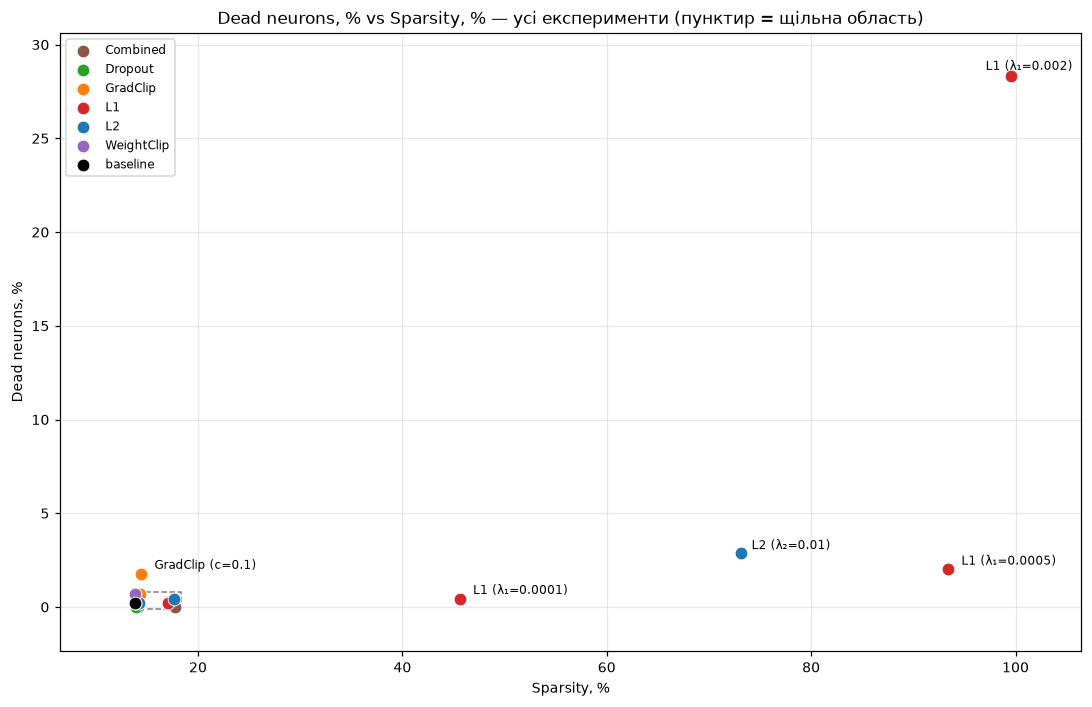

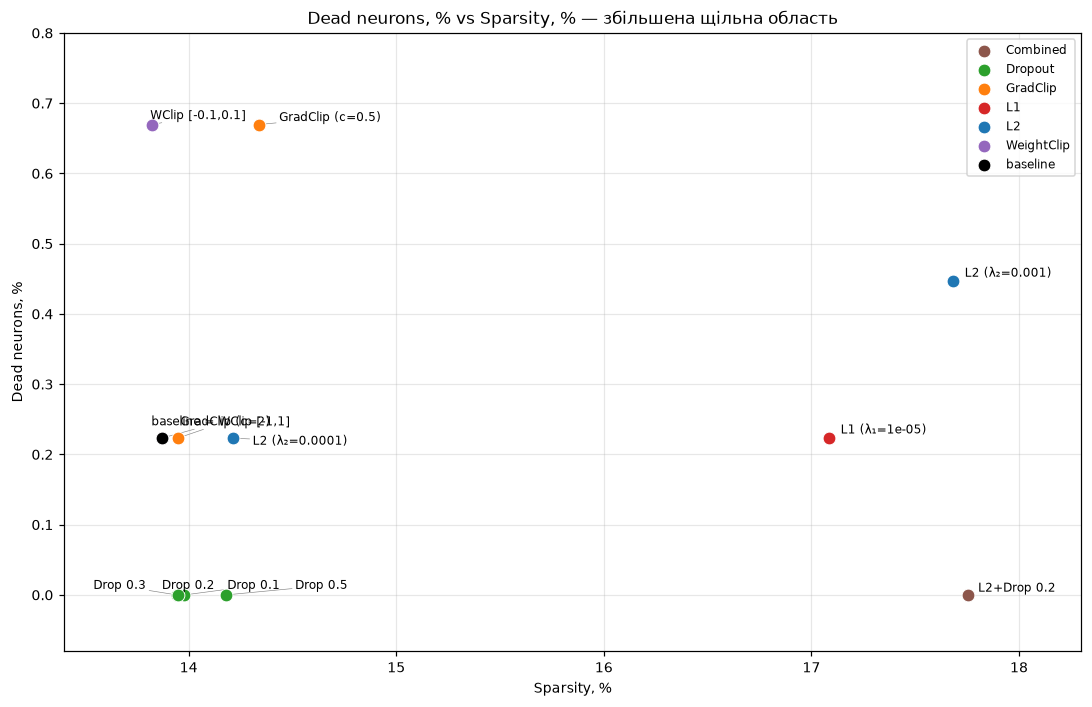

Діапазон dead neurons у всіх експериментах: 0.00% … 28.35%
dead % ↔ val acc : Pearson r = -0.741, Spearman ρ = -0.446
sparsity ↔ val acc : Pearson r = -0.638, Spearman ρ = -0.321
sparsity ↔ dead % : Pearson r = +0.680, Spearman ρ = +0.515
майже неактивні % ↔ val acc: Pearson r = +0.045, Spearman ρ = -0.079


,group,dead,rare,sparsity,val_acc,train_acc
name,,,,,,
L1 (λ1=0.002),L1,28.348,0.000,99.547,0.823,0.830
L2 (λ2=0.01),L2,2.902,3.348,73.178,0.856,0.866
L1 (λ1=0.0005),L1,2.009,2.009,93.435,0.855,0.864
Gradient clipping (c=0.1),GradClip,1.786,4.688,14.406,0.840,0.841
"Weight clipping [-0.1,0.1]",WeightClip,0.670,4.464,13.824,0.862,0.880
Gradient clipping (c=0.5),GradClip,0.670,5.580,14.337,0.864,0.887


In [24]:
from scipy.stats import spearmanr, pearsonr
try:
    from adjustText import adjust_text      # рекомендовано: %pip install adjustText (розставляє підписи без накладань)
except ImportError:
    adjust_text = None

df = pd.DataFrame([{"name": n, "group": r["group"], "dead": r["dead_pct"], "rare": r["rare_pct"], "sparsity": r["sparsity"], "val_acc": r["val_acc"], "train_acc": r["train_acc"]}
                   for n, r in RESULTS.items()])
palette = {"baseline": "black", "L1": "tab:red", "L2": "tab:blue", "Dropout": "tab:green", "WeightClip": "tab:purple", "GradClip": "tab:orange", "Combined": "tab:brown"}
def short(s):
    s = (s.replace("Без регуляризації", "baseline").replace("Gradient clipping", "GradClip").replace("Weight clipping", "WClip")
          .replace("Dropout", "Drop").replace("L2 + Drop", "L2+Drop"))
    return s.replace("(λ2=", "(λ₂=").replace("(λ1=", "(λ₁=")

def scatter_view(xk, yk, xl, yl, box, mode, figsize=(10, 6.5)):
    # mode="overview": усі точки, підписані лише ті, що поза щільною областю box (її обведено пунктиром)
    # mode="zoom"    : лише точки всередині box, підписані всі
    x0, x1, y0, y1 = box
    inside = df[xk].between(x0, x1) & df[yk].between(y0, y1)
    d = df[inside] if mode == "zoom" else df
    lab = d if mode == "zoom" else d[~inside]
    fig, a = plt.subplots(figsize=figsize)
    for g, sub in d.groupby("group"):
        a.scatter(sub[xk], sub[yk], c=palette[g], s=70, label=g, zorder=3, edgecolor="white", linewidth=0.6)
    # точки з однаковими координатами (напр. baseline і Weight clipping [-1,1]) підписуємо одним підписом
    lab = lab.assign(_x=lab[xk].round(4), _y=lab[yk].round(4))
    texts = []
    for k, ((xv, yv), grp) in enumerate(lab.groupby(["_x", "_y"])):
        txt = " = ".join(short(n) for n in grp["name"])
        if adjust_text is not None:
            texts.append(a.text(xv, yv, txt, fontsize=8))
        else:
            dx, dy = [(8, 6), (8, -12), (-8, 6), (-8, -12)][k % 4]
            a.annotate(txt, (xv, yv), xytext=(dx, dy + 8 * (k // 4 % 3)), textcoords="offset points", fontsize=8,
                       ha="left" if dx > 0 else "right", arrowprops=dict(arrowstyle="-", lw=0.4, color="gray"))
    if mode == "zoom":
        a.set_xlim(x0, x1); a.set_ylim(y0, y1)
    else:
        a.margins(x=0.08, y=0.08)
        a.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ls="--", ec="gray", lw=1, zorder=2))
    if adjust_text is not None and texts:
        adjust_text(texts, ax=a, arrowprops=dict(arrowstyle="-", lw=0.4, color="gray"))
    a.set(xlabel=xl, ylabel=yl, title=f"{yl} vs {xl} — " + ("усі експерименти (пунктир = щільна область)" if mode == "overview" else "збільшена щільна область"))
    a.legend(fontsize=8, loc="best"); plt.tight_layout(); plt.show()

# box = (x_min, x_max, y_min, y_max) щільної області; за потреби змінюйте
VIEWS = [("dead",     "val_acc", "Dead neurons, %", "Val accuracy",      (-0.05, 0.75, 0.858, 0.885)),
         ("sparsity", "val_acc", "Sparsity, %",     "Val accuracy",      (13.4, 18.3, 0.858, 0.885)),
         ("sparsity", "dead",    "Sparsity, %",     "Dead neurons, %",   (13.4, 18.3, -0.08, 0.80))]
for xk, yk, xl, yl, box in VIEWS:
    for mode in ("overview", "zoom"):
        scatter_view(xk, yk, xl, yl, box, mode)

def corr(x, y, label):
    if np.std(x) < 1e-12 or np.std(y) < 1e-12:
        print(f"{label}: кореляцію не визначено (одна зі змінних майже константна)"); return
    print(f"{label}: Pearson r = {pearsonr(x, y)[0]:+.3f}, Spearman ρ = {spearmanr(x, y)[0]:+.3f}")
print(f"Діапазон dead neurons у всіх експериментах: {df['dead'].min():.2f}% … {df['dead'].max():.2f}%")
corr(df["dead"], df["val_acc"], "dead % ↔ val acc ")
corr(df["sparsity"], df["val_acc"], "sparsity ↔ val acc ")
corr(df["sparsity"], df["dead"], "sparsity ↔ dead % ")
corr(df["rare"], df["val_acc"], "майже неактивні % ↔ val acc")
display(df.sort_values("dead", ascending=False).head(6).round(3).set_index("name"))

**Відповіді на питання з п. 4.3.**
1. **Чи є залежність між dead neurons і якістю?** Формально так, негативна: Pearson $r\approx-0.74$, Spearman $\rho\approx-0.45$. Але вона майже повністю визначається кількома екстремальними запусками з сильною регуляризацією (L1 $2\cdot10^{-3}$: 28 % dead, acc 0.823; L2 $10^{-2}$; L1 $5\cdot10^{-4}$); в основній масі експериментів dead ≈ 0–0.7 %, а accuracy коливається від 0.84 до 0.88 при практично однаковому dead. Різниця між Pearson і Spearman вказує, що зв'язок нелінійний і залежить від викидів.
2. **Чи призводить велика кількість мертвих нейронів до зниження точності?** Лише в тому сенсі, що обидва явища мають спільну причину — надмірно сильне обмеження моделі. Ми не ставили експерименту, що ізолює мертві нейрони як причину; наприклад, L2 $10^{-2}$ має 73 % sparsity та 2.9 % dead, і втрачає лише 2.4 п.п. accuracy. Також «майже неактивні» нейрони з accuracy не пов'язані ($r\approx+0.05$).
3. **Чи можуть моделі з однаковою кількістю мертвих нейронів мати різну точність?** Так. При 0 % dead: Dropout 0.1 → 0.8792 і Dropout 0.5 → 0.8606; при 0.22 % dead: baseline/L1 $10^{-5}$/gradient clipping $c=2$ → 0.880–0.882; при 0.67 %: weight clipping ±0.1 → 0.862 і gradient clipping $c=0.5$ → 0.864 (тут різниця лише 0.2 п.п.). Найбільша різниця за однакової кількості dead — у групі з 0 %: Dropout 0.1 vs Dropout 0.5, майже 2 п.п. І навпаки: близькі за accuracy моделі мають різний dead (0 % для Dropout 0.1 vs 0.22 % для бази).
4. **Чи є оптимальний баланс між sparsity і dead neurons?** Так, він існує, і він «помірний»: L1 $10^{-4}$ має sparsity 45.7 % при dead 0.45 % та accuracy 0.880 (на рівні бази), тобто модель можна розріджити утричі-вчетверо без втрати якості й без помітного зростання мертвих нейронів. Подальше збільшення sparsity (93 % → 99.6 %) супроводжується ростом dead (2 % → 28 %) і падінням accuracy. Кореляція sparsity↔dead додатна ($r\approx0.68$), але вона нелінійна: до ≈50 % sparsity dead майже не росте.

## 4.4 Чи завжди збільшення сили регуляризації покращує узагальнення?

Для L1, L2 і Dropout будуємо залежність train/val accuracy та розриву train–val від сили регуляризації (горизонтальна пунктирна лінія — базова модель, тобто нульова регуляризація).

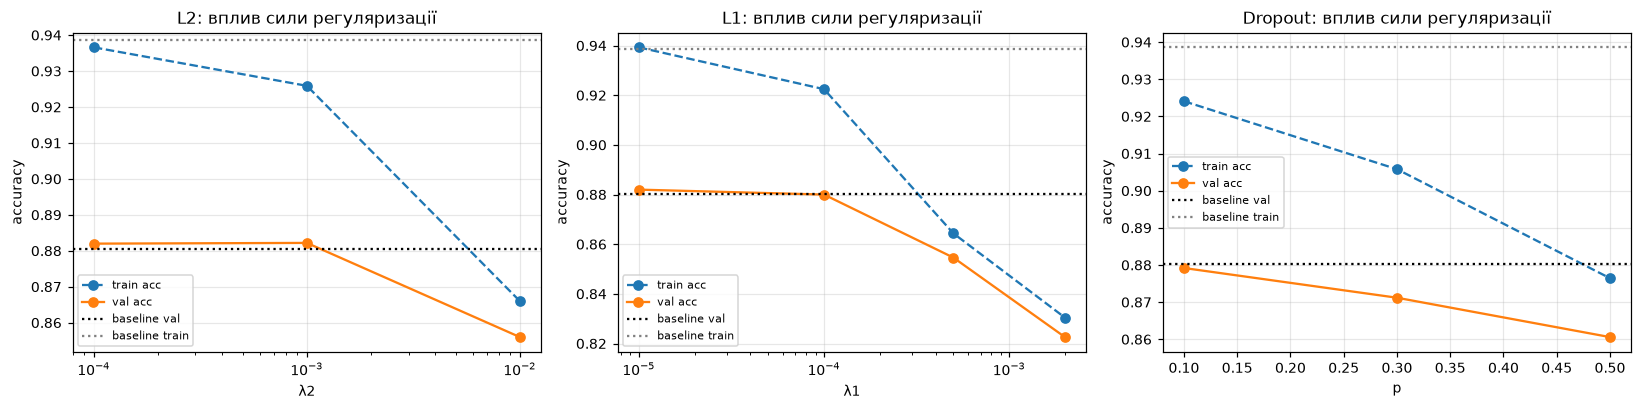

Train acc  Val acc     Gap  Δ val acc vs baseline  Val loss  Sparsity, %  Dead, %
Метод   Сила                                                                                      
L2      0.00010     0.9366   0.8820  0.0546                 0.0016    0.3396      14.2123   0.2232
        0.00100     0.9259   0.8822  0.0437                 0.0018    0.3392      17.6807   0.4464
        0.01000     0.8660   0.8560  0.0100                -0.0244    0.4312      73.1780   2.9018
L1      0.00001     0.9393   0.8820  0.0573                 0.0016    0.3426      17.0836   0.2232
        0.00010     0.9224   0.8800  0.0424                -0.0004    0.3392      45.6522   0.4464
        0.00050     0.8644   0.8546  0.0097                -0.0258    0.4201      93.4347   2.0089
        0.00200     0.8304   0.8226  0.0079                -0.0578    0.5079      99.5469  28.3482
Dropout 0.10000     0.9241   0.8792  0.0449                -0.0012    0.3424      13.9789   0.0000
        0.30000     0.9058   0.8712  0.0346                -0.0092    0.3634      13.9433   0.0000
        0.50000     0.8764   0.8606  0.0158                -0.0198    0.4011      14.1779   0.0000

In [25]:
b = RESULTS["Без регуляризації"]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (title, names, xs, xlab, logx) in zip(ax, (
        ("L2", [f"L2 (λ2={l:g})" for l in L2_VALUES], L2_VALUES, "λ2", True),
        ("L1", [f"L1 (λ1={l:g})" for l in L1_VALUES], L1_VALUES, "λ1", True),
        ("Dropout", [f"Dropout {p}" for p in DROPOUT_VALUES], DROPOUT_VALUES, "p", False))):
    a.plot(xs, [RESULTS[n]["train_acc"] for n in names], "o--", label="train acc")
    a.plot(xs, [RESULTS[n]["val_acc"] for n in names], "o-", label="val acc")
    a.axhline(b["val_acc"], color="k", ls=":", label="baseline val"); a.axhline(b["train_acc"], color="gray", ls=":", label="baseline train")
    if logx: a.set_xscale("log")
    a.set(title=f"{title}: вплив сили регуляризації", xlabel=xlab, ylabel="accuracy"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

rows = []
for grp, vals, fmt in (("L2", L2_VALUES, "L2 (λ2={:g})"), ("L1", L1_VALUES, "L1 (λ1={:g})"), ("Dropout", DROPOUT_VALUES, "Dropout {}")):
    for v in vals:
        r = RESULTS[fmt.format(v)]
        rows.append({"Метод": grp, "Сила": v, "Train acc": r["train_acc"], "Val acc": r["val_acc"], "Gap": r["train_acc"] - r["val_acc"],
                     "Δ val acc vs baseline": r["val_acc"] - b["val_acc"], "Val loss": r["val_loss"], "Sparsity, %": r["sparsity"], "Dead, %": r["dead_pct"]})
display(pd.DataFrame(rows).set_index(["Метод", "Сила"]).round(4))

**Відповідь: ні, збільшення сили регуляризації не завжди покращує узагальнення.** Залежність від сили **немонотонна**:

* **Слабка регуляризація** (L2 $10^{-4}$–$10^{-3}$, L1 $10^{-5}$–$10^{-4}$, Dropout 0.1): розрив train–val зменшується (5.8 → 4.2–5.5 п.п.), валідаційні loss і accuracy покращуються або залишаються на рівні бази (val loss 0.339–0.343 проти 0.344; accuracy 0.879–0.882). Ефект невеликий і в межах шуму (≈0.5 п.п.), але напрям правильний: це режим, у якому регуляризація знижує перенавчання.
* **Сильна регуляризація** (L2 $10^{-2}$, L1 $\ge5\cdot10^{-4}$, Dropout 0.3–0.5, жорсткий clipping): розрив train–val *майже зникає* (≈1 п.п. або менше), але лише тому, що **падає train accuracy** (до 0.83–0.88), а разом з нею падає і validation accuracy (0.823–0.861) та зростає val loss (0.42–0.51). Це **недонавчання**: модель не здатна навіть відтворити тренувальні дані.
* Для Dropout у діапазоні $p\ge0.1$ accuracy падає монотонно, тобто оптимум лежить при $p\le0.1$ або близько до нуля — за помірного перенавчання бази (≈6 п.п.) великий запас для регуляризації відсутній.

**Умови.** Регуляризація зменшує перенавчання, коли її штраф малий порівняно з втратою даних і модель має надлишкову ємність (великий розрив train–val, train acc ≈ 0.94). Вона призводить до недонавчання, коли штраф домінує: train accuracy падає разом із val accuracy, розрив зникає, а val loss зростає. Тому критерій «розрив train–val зменшився» **недостатній**: потрібно дивитись на сам рівень validation loss/accuracy.

*Обмеження.* Один seed, 5000 валідаційних об'єктів (SE ≈ 0.5 п.п.), 30 епох, підмножина 20 000 зображень. Різниці < 0.5 п.п. слід вважати незначущими; для надійних висновків потрібні кілька seed-ів і окрема тестова вибірка.

### Різниця між поняттями
| Поняття | Що це | Приклад з експериментів |
|---|---|---|
| **Мала величина ваг** | Ваги в середньому малі за модулем (mean \|W\| мала), але можуть бути не дуже близькими до нуля. | L2 $10^{-3}$: mean \|W\| 0.038 (база 0.049); модель працює не гірше за базу. |
| **Нульова / майже нульова вага** | Конкретна вага з \|W\| < 0.01 (sparsity). Вимірюється порогом; залежить від масштабу ваг. | He-ініціалізація: 14.5 % ваг уже «майже нульові»; L1 $10^{-4}$: 45.7 %. |
| **Неактивний нейрон** | Нейрон, який дає нуль на *частині* об'єктів або майже ніколи (наприклад, активний <1 % об'єктів), але не на всіх. Залежить від даних. | У базі ≈2.5 % «майже неактивних» нейронів, що не є мертвими; із Dropout 0.5 — 7.6 %. |
| **Мертвий нейрон** | ReLU-нейрон із $Z\le0$ для **всіх** об'єктів вибірки (в режимі inference): вихід 0 і градієнт 0. Визначається відносно вибірки. | L1 $2\cdot10^{-3}$: 28 % мертвих; Dropout — 0 %; у training-режимі випадково вимкнені нейрони хибно здаються мертвими. |
| **Надмірно регуляризована модель** | Штраф настільки сильний, що модель недонавчена: train і val accuracy низькі, розрив малий. | L1 $2\cdot10^{-3}$ (val 0.823, sparsity 99.6 %), L2 $10^{-2}$, Dropout 0.5, gradient clipping $c=0.1$. |

Ці поняття не еквівалентні: модель із **багатьма малими вагами** (L2) може мати **0 мертвих нейронів**; модель із **високою sparsity** (L1 $10^{-4}$, 46 %) може не втрачати точності; **неактивний** нейрон не обов'язково мертвий (нейрон, мертвий на train, може активуватися на нових даних — це було помічено у запуску з weight clipping ±0.1); **мертвих** нейронів може не бути і в **надмірно регуляризованій** моделі (Dropout 0.5 недонавчений, але dead = 0).

## Загальні висновки

1. Реалізована з нуля на NumPy MLP (784-256-128-64-10, ReLU, Softmax, CE, SGD, He) навчається до val accuracy ≈ 0.88; градієнти backprop збігаються з чисельними (відносна похибка ≲ 10⁻⁷), збереження/відновлення ваг відтворює виходи точно (різниця 0).
2. Найкращі результати дають **слабкі** регуляризатори (L2 $10^{-3}$, L1 $10^{-5}$, gradient clipping $c=2$), але їх виграш над базою (≤ 0.2 п.п.) знаходиться в межах статистичної похибки; Dropout 0.1 (0.8792) від бази (0.8804) практично не відрізняється (−0.1 п.п.). Сильні варіанти надійно погіршують якість (недонавчання).
3. **L1** — найефективніший спосіб розрідити ваги без втрати якості ($\lambda_1=10^{-4}$: sparsity 46 %, accuracy як у бази). **L2** зменшує величину ваг, але не створює істинної розрідженості. **Dropout** і **gradient clipping** майже не змінюють розподіл ваг; **weight clipping ±1** у цьому налаштуванні не діє, а жорсткіший ±0.1 шкодить якості.
4. Мертві нейрони виникають лише за сильної регуляризації (L1, L2, малі пороги gradient clipping); Dropout їх не створює, якщо діагностику проводити в inference-режимі. Зв'язок dead neurons ↔ accuracy в нашому експерименті — це наслідок спільної причини (надмірне обмеження), а не доведений причинний вплив.
5. Комбінація L2 + Dropout 0.2 не дала синергії (0.8736 проти 0.8822 для L2 і 0.8764 для Dropout 0.2): методи перекриваються, і сумарне обмеження починає знижувати ємність.

*Відтворюваність:* всі seed-и зафіксовані (дані, ініціалізація, перемішування, маски dropout). Дані завантажуються автоматично; якщо немає інтернету, можна покласти файли `train-images-idx3-ubyte.gz` та `train-labels-idx1-ubyte.gz` у папку `data/`.